# Análise por épocas — task decision-making (DM)
## Piloto: sub-001 e sub-002

### Objetivo
Inspecionar e analisar as épocas da task DM já guardadas para
os dois participantes do piloto, antes de preparar a aplicação
à amostra completa.

### Âmbito
- Participantes: `sub-001` e `sub-002`.
- Runs: 1 e 2, conforme os ficheiros disponíveis.
- Primeiro passo: localizar os ficheiros guardados.
- Passos seguintes: verificar condições, eventos, janelas temporais,
  baseline, canais e número de épocas antes de calcular curvas médias.

### Independência do notebook
Este notebook não depende das variáveis do notebook de auditoria.
Os caminhos e as configurações necessários são definidos aqui.

### Limites
- O pré-processamento não é repetido nesta etapa.
- A existência de ficheiros guardados não confirma a sua validade.
- Não se aplicam novas correções ou exclusões automaticamente.
- A auditoria dos marcadores da amostra completa continua pendente.
- Os resultados deste piloto não são resultados de grupo.

---

## Etapa E-DM.0 — Configuração e verificação das pastas

### Objetivo
Definir a pasta do estudo e confirmar a disponibilidade das pastas
dos dois participantes.

### Entrada
- Caminho da pasta do estudo na OneDrive partilhada.

### Procedimento
1. Definir o caminho da pasta do estudo.
2. Confirmar que a pasta está disponível.
3. Confirmar a existência das pastas `sub-001` e `sub-002`.

### Saída
- `base_estudo_dm`: caminho da pasta do estudo.
- `pastas_piloto_dm`: caminhos dos dois participantes.

### Limites
- Não se pesquisam nem se abrem ficheiros nesta etapa.
- Não se criam pastas e não se escrevem ficheiros.

In [1]:
from pathlib import Path


base_estudo_dm = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

sujeitos_piloto_dm = ("sub-001", "sub-002")

if not base_estudo_dm.is_dir():
    raise FileNotFoundError(
        f"Pasta do estudo inexistente ou indisponível:\n"
        f"{base_estudo_dm}"
    )

pastas_piloto_dm = {
    sujeito: base_estudo_dm / sujeito
    for sujeito in sujeitos_piloto_dm
}

for sujeito, pasta in pastas_piloto_dm.items():
    if not pasta.is_dir():
        raise FileNotFoundError(
            f"Pasta de {sujeito} inexistente ou indisponível:\n"
            f"{pasta}"
        )

print("ETAPA E-DM.0 — CONFIGURAÇÃO DO PILOTO")
print(f"\nPasta do estudo: {base_estudo_dm}")

for sujeito, pasta in pastas_piloto_dm.items():
    print(f"\n{sujeito}: pasta disponível")
    print(pasta)

print("\nNenhum ficheiro aberto ou escrito.")

ETAPA E-DM.0 — CONFIGURAÇÃO DO PILOTO

Pasta do estudo: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI

sub-001: pasta disponível
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001

sub-002: pasta disponível
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-002

Nenhum ficheiro aberto ou escrito.


## Etapa E-DM.1 — Inventário dos ficheiros de épocas do piloto

### Objetivo
Localizar os ficheiros potencialmente correspondentes às épocas
guardadas para `sub-001` e `sub-002`, preparando a seleção dos
ficheiros da task decision-making (DM).

### Entradas
- `pastas_piloto_dm`: caminhos dos participantes, definidos e
  verificados na Etapa E-DM.0.

### Procedimento
1. Pesquisar recursivamente apenas as pastas dos dois participantes.
2. Identificar ficheiros com extensão `.fif` ou `.fif.gz` cujo
   nome contenha `epo`, sem distinguir maiúsculas de minúsculas.
3. Registar participante, nome, caminho relativo, caminho completo
   e tamanho de cada candidato.
4. Registar eventuais erros de acesso.
5. Apresentar os candidatos encontrados por participante.

### Saídas
- `df_edm1_candidatos_epochs`: inventário dos ficheiros candidatos.
- `df_edm1_erros`: erros de acesso encontrados durante a pesquisa.

### Limites
- O nome e a extensão não confirmam que o ficheiro contenha épocas
  válidas ou pertença à task DM.
- Podem ser encontrados ficheiros da task Stroop, versões diferentes
  ou partes de um mesmo conjunto de ficheiros.
- Não se atribuem automaticamente task, run ou fase.
- A ausência de candidatos não demonstra ausência de épocas:
  estas podem ter outros nomes, formatos ou localizações.
- Não se lê o conteúdo dos ficheiros.
- Não se aplica pré-processamento, baseline ou rejeição de épocas.
- Não se escrevem ficheiros.

In [2]:
import os
from pathlib import Path

import pandas as pd


if "pastas_piloto_dm" not in globals():
    raise RuntimeError("Executa primeiro a Etapa E-DM.0.")

ficheiros_edm1 = []
erros_edm1 = []

for sujeito, pasta in sorted(pastas_piloto_dm.items()):
    pasta = Path(pasta)

    if not pasta.is_dir():
        raise FileNotFoundError(
            f"Pasta inexistente ou indisponível: {pasta}"
        )

    def registar_erro_edm1(erro, sujeito_atual=sujeito):
        erros_edm1.append({
            "sujeito": sujeito_atual,
            "caminho": str(getattr(erro, "filename", "") or ""),
            "erro": f"{type(erro).__name__}: {erro}",
        })

    for diretorio, subpastas, nomes in os.walk(
        pasta,
        topdown=True,
        onerror=registar_erro_edm1,
        followlinks=False,
    ):
        subpastas.sort()

        for nome in sorted(nomes):
            nome_normalizado = nome.lower()

            if not (
                "epo" in nome_normalizado
                and nome_normalizado.endswith((".fif", ".fif.gz"))
            ):
                continue

            caminho = Path(diretorio) / nome

            try:
                tamanho = caminho.stat().st_size
            except OSError as erro:
                registar_erro_edm1(erro)
                tamanho = pd.NA

            ficheiros_edm1.append({
                "sujeito": sujeito,
                "nome": nome,
                "caminho_relativo": str(caminho.relative_to(pasta)),
                "tamanho_bytes": tamanho,
                "caminho": str(caminho),
            })


df_edm1_candidatos_epochs = pd.DataFrame(
    ficheiros_edm1,
    columns=[
        "sujeito", "nome", "caminho_relativo",
        "tamanho_bytes", "caminho",
    ],
).sort_values(
    ["sujeito", "caminho_relativo"],
    ignore_index=True,
)

df_edm1_erros = pd.DataFrame(
    erros_edm1,
    columns=["sujeito", "caminho", "erro"],
)

print("ETAPA E-DM.1 — INVENTÁRIO DOS FICHEIROS DE ÉPOCAS")

for sujeito in sorted(pastas_piloto_dm):
    bloco = df_edm1_candidatos_epochs.loc[
        df_edm1_candidatos_epochs["sujeito"].eq(sujeito)
    ]

    print(f"\n{sujeito} | candidatos encontrados: {len(bloco)}")

    if bloco.empty:
        print("Nenhum candidato com os critérios definidos.")
    else:
        print(
            bloco[
                ["caminho_relativo", "tamanho_bytes"]
            ].to_string(index=False)
        )

print(f"\nErros de acesso: {len(df_edm1_erros)}")
if not df_edm1_erros.empty:
    print(df_edm1_erros.to_string(index=False))

print("\nNenhum conteúdo lido e nenhum ficheiro escrito.")
print("Nenhuma versão, fase ou run selecionada automaticamente.")

ETAPA E-DM.1 — INVENTÁRIO DOS FICHEIROS DE ÉPOCAS

sub-001 | candidatos encontrados: 10
                                                                                                                                   caminho_relativo  tamanho_bytes
  fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_decisao_inspect_base-epo.fif         365046
fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_decisao_inspect_nobase-epo.fif         365006
    fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_video_inspect_base-epo.fif         365025
  fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_video_inspect_nobase-epo.fif         364985
  fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01

## Etapa E-DM.2 — Seleção dos ficheiros do piloto atual

### Objetivo
Selecionar os ficheiros de épocas da task decision-making (DM)
pertencentes a `pilot_dm_epochs_v01`, separando-os dos ficheiros
da tentativa anterior de pré-processamento single-subject.

### Entradas
- `df_edm1_candidatos_epochs`: inventário da Etapa E-DM.1.
- Esclarecimento do investigador: a pasta `v02` do `sub-001`
  corresponde à tentativa anterior e não será utilizada nesta análise.

### Procedimento
1. Selecionar apenas os candidatos localizados na pasta
   `fNIRS_epochs_derivatives/pilot_dm_epochs_v01`.
2. Identificar participante, run, fase e versão pelo nome do ficheiro.
3. Confirmar que o participante no nome corresponde ao inventário.
4. Confirmar a presença das 16 combinações esperadas:
   - Dois participantes: `sub-001` e `sub-002`.
   - Duas runs: 1 e 2.
   - Duas fases: vídeo e decisão.
   - Duas versões: `base` e `nobase`.
5. Manter os restantes candidatos numa tabela separada.

### Saídas
- `df_edm2_selecionados`: os 16 ficheiros do piloto atual.
- `df_edm2_fora_ambito`: candidatos não utilizados nesta análise.

### Limites
- A seleção estabelece o conjunto de ficheiros a inspecionar;
  não confirma a qualidade do seu conteúdo.
- As classificações de fase e versão são extraídas dos nomes.
- Os rótulos `base` e `nobase` ainda não foram confirmados através
  das propriedades dos objetos de épocas.
- As duas versões não são conjuntos independentes de ensaios
  e não serão reunidas como se fossem épocas adicionais.
- Não se lê o conteúdo dos ficheiros.
- Não se apagam, alteram ou escrevem ficheiros.

In [3]:
import re
from itertools import product
from pathlib import Path

import pandas as pd


if "df_edm1_candidatos_epochs" not in globals():
    raise RuntimeError("Executa primeiro a Etapa E-DM.1.")

def pertence_ao_piloto_edm2(caminho_relativo):
    partes = Path(caminho_relativo).parts
    return any(
        partes[i:i + 2]
        == ("fNIRS_epochs_derivatives", "pilot_dm_epochs_v01")
        for i in range(len(partes) - 1)
    )


mascara_edm2 = df_edm1_candidatos_epochs[
    "caminho_relativo"
].map(pertence_ao_piloto_edm2)

df_edm2_selecionados = (
    df_edm1_candidatos_epochs.loc[mascara_edm2].copy()
)
df_edm2_fora_ambito = (
    df_edm1_candidatos_epochs.loc[~mascara_edm2].copy()
)

padrao_edm2 = re.compile(
    r"^(?P<sujeito_nome>sub-\d{3})_ses-01_tk-dm_"
    r"run-(?P<run>[12])_nirs_\d+_"
    r"(?P<fase>video|decisao)_inspect_"
    r"(?P<versao>base|nobase)-epo\.fif(?:\.gz)?$"
)

campos_edm2 = df_edm2_selecionados["nome"].str.extract(
    padrao_edm2
)

if campos_edm2.isna().any().any():
    nomes_invalidos = df_edm2_selecionados.loc[
        campos_edm2.isna().any(axis=1), "nome"
    ].tolist()
    raise RuntimeError(
        f"Nomes não reconhecidos no piloto: {nomes_invalidos}"
    )

if not campos_edm2["sujeito_nome"].eq(
    df_edm2_selecionados["sujeito"]
).all():
    raise RuntimeError(
        "Há diferenças entre o participante no nome e no inventário."
    )

df_edm2_selecionados["run"] = campos_edm2["run"].astype(int)
df_edm2_selecionados["fase"] = campos_edm2["fase"]
df_edm2_selecionados["versao"] = campos_edm2["versao"]

chaves_edm2 = ["sujeito", "run", "fase", "versao"]

if df_edm2_selecionados.duplicated(chaves_edm2).any():
    raise RuntimeError(
        "Existe mais de um ficheiro para a mesma combinação."
    )

esperadas_edm2 = set(product(
    ["sub-001", "sub-002"],
    [1, 2],
    ["video", "decisao"],
    ["base", "nobase"],
))

observadas_edm2 = set(
    df_edm2_selecionados[chaves_edm2].itertuples(
        index=False, name=None
    )
)

if observadas_edm2 != esperadas_edm2:
    raise RuntimeError(
        f"Combinações em falta: "
        f"{sorted(esperadas_edm2 - observadas_edm2)}\n"
        f"Combinações inesperadas: "
        f"{sorted(observadas_edm2 - esperadas_edm2)}"
    )

df_edm2_selecionados = (
    df_edm2_selecionados
    .sort_values(chaves_edm2)
    .reset_index(drop=True)
)

print("ETAPA E-DM.2 — SELEÇÃO DO PILOTO ATUAL")
print(
    df_edm2_selecionados[
        chaves_edm2 + ["nome"]
    ].to_string(index=False)
)

print(f"\nFicheiros selecionados: {len(df_edm2_selecionados)}")
print(f"Ficheiros fora do âmbito: {len(df_edm2_fora_ambito)}")

if not df_edm2_fora_ambito.empty:
    print(
        df_edm2_fora_ambito[
            ["sujeito", "caminho_relativo"]
        ].to_string(index=False)
    )

print("\nAs 16 combinações esperadas estão presentes.")
print("Nenhum conteúdo lido e nenhum ficheiro alterado ou escrito.")

ETAPA E-DM.2 — SELEÇÃO DO PILOTO ATUAL
sujeito  run    fase versao                                                               nome
sub-001    1 decisao   base   sub-001_ses-01_tk-dm_run-1_nirs_001_decisao_inspect_base-epo.fif
sub-001    1 decisao nobase sub-001_ses-01_tk-dm_run-1_nirs_001_decisao_inspect_nobase-epo.fif
sub-001    1   video   base     sub-001_ses-01_tk-dm_run-1_nirs_001_video_inspect_base-epo.fif
sub-001    1   video nobase   sub-001_ses-01_tk-dm_run-1_nirs_001_video_inspect_nobase-epo.fif
sub-001    2 decisao   base   sub-001_ses-01_tk-dm_run-2_nirs_001_decisao_inspect_base-epo.fif
sub-001    2 decisao nobase sub-001_ses-01_tk-dm_run-2_nirs_001_decisao_inspect_nobase-epo.fif
sub-001    2   video   base     sub-001_ses-01_tk-dm_run-2_nirs_001_video_inspect_base-epo.fif
sub-001    2   video nobase   sub-001_ses-01_tk-dm_run-2_nirs_001_video_inspect_nobase-epo.fif
sub-002    1 decisao   base   sub-002_ses-01_tk-dm_run-1_nirs_002_decisao_inspect_base-epo.fif
sub-002    

## Etapa E-DM.3 — Inspeção estrutural e visualização das épocas

### Objetivo
Inspecionar os 16 ficheiros selecionados da task decision-making
(DM), antes de calcular curvas médias ou aplicar novas operações.

### Entrada
- `df_edm2_selecionados`: ficheiros do piloto atual selecionados
  na Etapa E-DM.2.

### Procedimento
1. Ler os ficheiros com `preload=False`.
2. Registar:
   - Número de épocas presentes.
   - Frequência de amostragem.
   - Limites temporais e número de amostras por época.
   - Número e tipos de canais.
   - Canais assinalados como maus.
   - Baseline registada no objeto.
   - Dicionário de eventos e contagens dos códigos presentes.
   - Colunas de metadata, quando existam.
   - Motivos não vazios presentes no histórico `drop_log`.
3. Registar erros e avisos de leitura.
4. Mostrar no output do notebook:
   - Contagens de épocas por participante, run, fase e versão.
   - Janelas temporais e baseline registada em cada ficheiro.

### Saídas
- `epochs_edm3`: objetos de épocas, indexados por
  `(sujeito, run, fase, versao)`.
- `df_edm3_estrutura`: resumo estrutural por ficheiro.
- `df_edm3_eventos`: contagens dos códigos de evento presentes.
- `df_edm3_drop_log`: contagens dos motivos não vazios registados.
- Dois gráficos apresentados no output do notebook.

### Limites
- Não se calculam ainda curvas médias de HbO ou HbR.
- Não se aplica nova baseline, filtragem ou rejeição.
- Os códigos numéricos dos eventos são apresentados como guardados:
  não se presume que correspondam diretamente aos códigos SNIRF.
- O campo `baseline` documenta a configuração guardada no objeto,
  não constitui uma auditoria completa do processamento anterior.
- Motivos como `IGNORED` no `drop_log` não são automaticamente
  interpretados como rejeições por má qualidade.
- As versões `base` e `nobase` são inspecionadas separadamente,
  não reunidas como ensaios adicionais.
- Não se escrevem ficheiros.

ETAPA E-DM.3 — ESTRUTURA DAS ÉPOCAS
MNE: 1.12.1


,sujeito,run,fase,versao,leitura_ok,erro,avisos,n_epochs,sfreq_hz,tmin_s,tmax_s,n_amostras_epoca,n_canais,tipos_canal,n_canais_maus,canais_maus,baseline,event_id,metadata_colunas
0,sub-001,1,decisao,base,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,"(-1.0, 0.0)","{""decisao"": 130}",sujeito; run; tentativa_na_run; onset_fixacao_...
1,sub-001,1,decisao,nobase,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,None,"{""decisao"": 130}",sujeito; run; tentativa_na_run; onset_fixacao_...
2,sub-001,1,video,base,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,"(-1.0, 0.0)","{""video"": 120}",sujeito; run; tentativa_na_run; onset_fixacao_...
3,sub-001,1,video,nobase,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,None,"{""video"": 120}",sujeito; run; tentativa_na_run; onset_fixacao_...
4,sub-001,2,decisao,base,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,"(-1.0, 0.0)","{""decisao"": 130}",sujeito; run; tentativa_na_run; onset_fixacao_...
5,sub-001,2,decisao,nobase,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,None,"{""decisao"": 130}",sujeito; run; tentativa_na_run; onset_fixacao_...
6,sub-001,2,video,base,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,"(-1.0, 0.0)","{""video"": 120}",sujeito; run; tentativa_na_run; onset_fixacao_...
7,sub-001,2,video,nobase,True,,,10,10.172526,-0.98304,10.027008,113,38,"{""hbo"": 19, ""hbr"": 19}",0,,None,"{""video"": 120}",sujeito; run; tentativa_na_run; onset_fixacao_...
8,sub-002,1,decisao,base,True,,,10,10.172526,-0.98304,10.027008,113,40,"{""hbo"": 20, ""hbr"": 20}",0,,"(-1.0, 0.0)","{""decisao"": 130}",sujeito; run; tentativa_na_run; onset_fixacao_...
9,sub-002,1,decisao,nobase,True,,,10,10.172526,-0.98304,10.027008,113,40,"{""hbo"": 20, ""hbr"": 20}",0,,None,"{""decisao"": 130}",sujeito; run; tentativa_na_run; onset_fixacao_...



EVENTOS PRESENTES NOS FICHEIROS


,sujeito,run,fase,versao,codigo_guardado,rotulos,n_epochs
0,sub-001,1,decisao,base,130,decisao,10
1,sub-001,1,decisao,nobase,130,decisao,10
2,sub-001,1,video,base,120,video,10
3,sub-001,1,video,nobase,120,video,10
4,sub-001,2,decisao,base,130,decisao,10
5,sub-001,2,decisao,nobase,130,decisao,10
6,sub-001,2,video,base,120,video,10
7,sub-001,2,video,nobase,120,video,10
8,sub-002,1,decisao,base,130,decisao,10
9,sub-002,1,decisao,nobase,130,decisao,10



MOTIVOS NÃO VAZIOS NO DROP_LOG
Nenhum motivo não vazio registado.


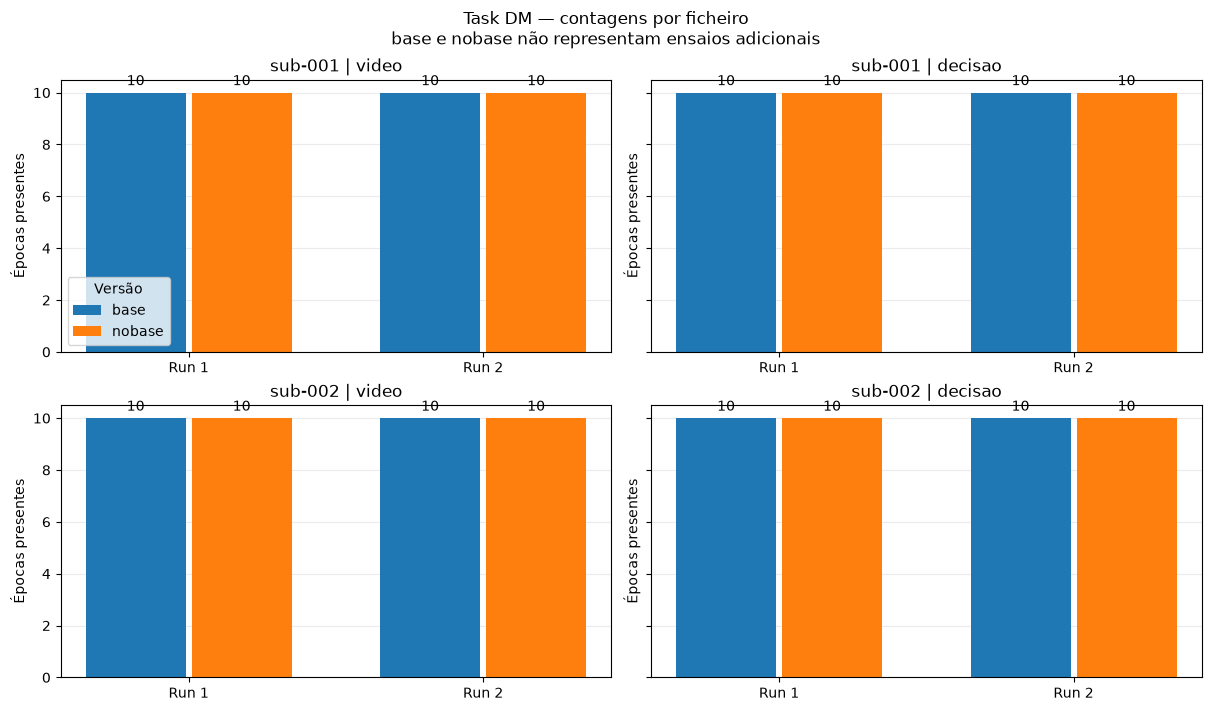

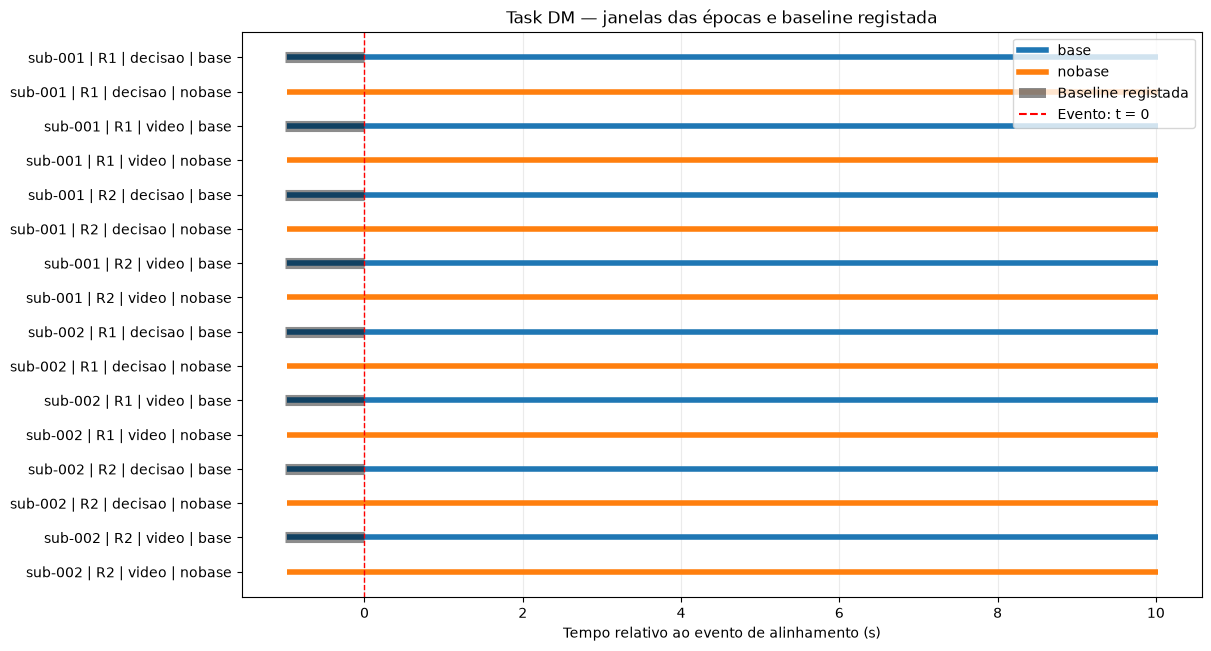


Nenhuma nova baseline ou rejeição aplicada.
Nenhum ficheiro escrito.


In [4]:
import json
import warnings
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import mne
import pandas as pd
from IPython.display import display


if "df_edm2_selecionados" not in globals():
    raise RuntimeError("Executa primeiro a Etapa E-DM.2.")

epochs_edm3 = {}
estrutura_edm3 = []
eventos_edm3 = []
drop_log_edm3 = []

for r in df_edm2_selecionados.itertuples(index=False):
    chave = (r.sujeito, r.run, r.fase, r.versao)
    identificacao = dict(
        sujeito=r.sujeito,
        run=r.run,
        fase=r.fase,
        versao=r.versao,
    )
    linha = {
        **identificacao,
        "leitura_ok": False,
        "erro": "",
        "avisos": "",
    }

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")

        try:
            ep = mne.read_epochs(
                r.caminho, preload=False, verbose=False
            )

            tipos = Counter(ep.get_channel_types())
            contagens = Counter(int(c) for c in ep.events[:, 2])

            linha.update({
                "leitura_ok": True,
                "n_epochs": len(ep.events),
                "sfreq_hz": float(ep.info["sfreq"]),
                "tmin_s": float(ep.tmin),
                "tmax_s": float(ep.tmax),
                "n_amostras_epoca": len(ep.times),
                "n_canais": len(ep.ch_names),
                "tipos_canal": json.dumps(
                    dict(tipos), sort_keys=True
                ),
                "n_canais_maus": len(ep.info["bads"]),
                "canais_maus": "; ".join(ep.info["bads"]),
                "baseline": str(ep.baseline),
                "event_id": json.dumps(
                    {k: int(v) for k, v in ep.event_id.items()},
                    ensure_ascii=False,
                    sort_keys=True,
                ),
                "metadata_colunas": (
                    "; ".join(map(str, ep.metadata.columns))
                    if ep.metadata is not None else ""
                ),
            })

            for codigo, n in sorted(contagens.items()):
                rotulos = [
                    nome for nome, valor in ep.event_id.items()
                    if int(valor) == codigo
                ]
                eventos_edm3.append({
                    **identificacao,
                    "codigo_guardado": codigo,
                    "rotulos": "; ".join(rotulos),
                    "n_epochs": n,
                })

            motivos = Counter(
                motivo
                for entrada in ep.drop_log
                for motivo in entrada
            )
            for motivo, n in sorted(motivos.items()):
                drop_log_edm3.append({
                    **identificacao,
                    "motivo": motivo,
                    "n_ocorrencias": n,
                })

            epochs_edm3[chave] = ep

        except Exception as erro:
            linha["erro"] = f"{type(erro).__name__}: {erro}"

    linha["avisos"] = " | ".join(
        dict.fromkeys(str(a.message) for a in avisos)
    )
    estrutura_edm3.append(linha)


df_edm3_estrutura = pd.DataFrame(estrutura_edm3)
df_edm3_eventos = pd.DataFrame(
    eventos_edm3,
    columns=[
        "sujeito", "run", "fase", "versao",
        "codigo_guardado", "rotulos", "n_epochs",
    ],
)
df_edm3_drop_log = pd.DataFrame(
    drop_log_edm3,
    columns=[
        "sujeito", "run", "fase", "versao",
        "motivo", "n_ocorrencias",
    ],
)

print("ETAPA E-DM.3 — ESTRUTURA DAS ÉPOCAS")
print(f"MNE: {mne.__version__}")
display(df_edm3_estrutura)

print("\nEVENTOS PRESENTES NOS FICHEIROS")
display(df_edm3_eventos)

print("\nMOTIVOS NÃO VAZIOS NO DROP_LOG")
if df_edm3_drop_log.empty:
    print("Nenhum motivo não vazio registado.")
else:
    display(df_edm3_drop_log)

problemas = df_edm3_estrutura.loc[
    ~df_edm3_estrutura["leitura_ok"]
    | df_edm3_estrutura["avisos"].ne("")
]
if not problemas.empty:
    print("\nERROS OU AVISOS A REVER")
    display(problemas[
        ["sujeito", "run", "fase", "versao", "erro", "avisos"]
    ])


validos = df_edm3_estrutura.loc[
    df_edm3_estrutura["leitura_ok"]
].copy()

cores = {"base": "tab:blue", "nobase": "tab:orange"}

if not validos.empty:
    fig, eixos = plt.subplots(
        2, 2, figsize=(12, 7), sharey=True,
        constrained_layout=True
    )

    for i, sujeito in enumerate(["sub-001", "sub-002"]):
        for j, fase in enumerate(["video", "decisao"]):
            ax = eixos[i, j]

            for versao, deslocamento in [
                ("base", -0.18), ("nobase", 0.18)
            ]:
                bloco = validos.loc[
                    validos["sujeito"].eq(sujeito)
                    & validos["fase"].eq(fase)
                    & validos["versao"].eq(versao)
                ].sort_values("run")

                barras = ax.bar(
                    bloco["run"] + deslocamento,
                    bloco["n_epochs"],
                    width=0.34,
                    color=cores[versao],
                    label=versao,
                )
                ax.bar_label(barras, fmt="%.0f", padding=3)

            ax.set_title(f"{sujeito} | {fase}")
            ax.set_xticks([1, 2], ["Run 1", "Run 2"])
            ax.set_ylabel("Épocas presentes")
            ax.set_ylim(bottom=0)
            ax.margins(y=0.2)
            ax.grid(axis="y", alpha=0.25)
            ax.set_axisbelow(True)

    eixos[0, 0].legend(title="Versão")
    fig.suptitle(
        "Task DM — contagens por ficheiro\n"
        "base e nobase não representam ensaios adicionais"
    )
    plt.show()

    fig, ax = plt.subplots(
        figsize=(12, max(6, 0.4 * len(validos))),
        constrained_layout=True,
    )

    etiquetas = []

    for y, r in enumerate(validos.itertuples(index=False)):
        chave = (r.sujeito, r.run, r.fase, r.versao)
        ep = epochs_edm3[chave]

        ax.hlines(
            y, ep.tmin, ep.tmax,
            color=cores[r.versao], linewidth=4,
        )

        if ep.baseline is not None:
            inicio, fim = ep.baseline
            inicio = ep.tmin if inicio is None else inicio
            fim = ep.tmax if fim is None else fim

            ax.hlines(
                y, inicio, fim,
                color="black", linewidth=8, alpha=0.45,
            )

        etiquetas.append(
            f"{r.sujeito} | R{r.run} | {r.fase} | {r.versao}"
        )

    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_yticks(range(len(etiquetas)), etiquetas)
    ax.invert_yaxis()
    ax.set_xlabel("Tempo relativo ao evento de alinhamento (s)")
    ax.set_title("Task DM — janelas das épocas e baseline registada")
    ax.grid(axis="x", alpha=0.25)

    ax.legend(
        handles=[
            Line2D([0], [0], color=cores["base"], lw=4, label="base"),
            Line2D(
                [0], [0], color=cores["nobase"], lw=4, label="nobase"
            ),
            Patch(
                facecolor="black", alpha=0.45,
                label="Baseline registada",
            ),
            Line2D(
                [0], [0], color="red", linestyle="--",
                label="Evento: t = 0",
            ),
        ],
        loc="best",
    )
    plt.show()
else:
    print("\nSem ficheiros legíveis para visualizar.")

print("\nNenhuma nova baseline ou rejeição aplicada.")
print("Nenhum ficheiro escrito.")

## Etapa E-DM.4 — Metadados e identidade dos canais

### Objetivo
Identificar a informação disponível sobre os ensaios e os canais
presentes nas épocas da task decision-making (DM), antes de
calcular curvas médias.

### Entrada
- `epochs_edm3`: objetos de épocas lidos na Etapa E-DM.3.

### Procedimento
1. Selecionar as versões `nobase` para esta inspeção, sem as alterar.
2. Mostrar os nomes completos das colunas de metadata.
3. Mostrar as primeiras três linhas de metadata de cada objeto.
4. Inventariar os nomes e tipos dos canais por participante,
   run e fase.
5. Comparar a lista ordenada de canais entre vídeo e decisão
   dentro de cada run.
6. Representar a presença e ausência dos canais numa matriz,
   apresentada no output do notebook.

### Saídas
- `df_edm4_metadata_colunas`: inventário das colunas de metadata.
- `df_edm4_canais`: nomes e tipos dos canais por objeto.
- `df_edm4_comparacao_fases`: comparação das listas de canais
  entre vídeo e decisão dentro de cada run.
- Matriz gráfica de presença dos canais nas versões `nobase`.

### Limites
- Inspecionar as versões `nobase` não implica escolhê-las como
  versão final para a análise.
- Não se confirma ainda a correspondência entre `base` e `nobase`.
- A presença de um canal não constitui uma avaliação da sua qualidade.
- A ausência de um canal não identifica a razão da sua remoção.
- Não se definem regiões de interesse nem se combinam canais.
- Não se calcula uma média entre participantes ou fases.
- Não se aplica baseline, rejeição ou novo pré-processamento.
- Não se escrevem ficheiros.

ETAPA E-DM.4 — METADADOS DAS VERSÕES NOBASE

sub-001 | run 1 | video
Linhas de metadata: 10 | Épocas presentes: 10
Colunas completas:
  - sujeito
  - run
  - tentativa_na_run
  - onset_fixacao_pre_s
  - onset_video_s
  - onset_decisao_s
  - onset_fixacao_pos_s
  - onset_fase_seguinte_s
  - intervalo_110_120_s
  - intervalo_120_130_s
  - intervalo_130_150_s
  - intervalo_pos_s
  - fase_alinhamento
  - codigo_evento
  - onset_evento_s
  - erro_arredondamento_ms

Primeiras três linhas:
sujeito  run  tentativa_na_run  onset_fixacao_pre_s  onset_video_s  onset_decisao_s  onset_fixacao_pos_s  onset_fase_seguinte_s  intervalo_110_120_s  intervalo_120_130_s  intervalo_130_150_s  intervalo_pos_s fase_alinhamento  codigo_evento  onset_evento_s  erro_arredondamento_ms
sub-001    1                 1            40.211998      50.311474        80.004845            82.316536              84.814629            10.099476            29.693371             2.311691         2.498093            video        

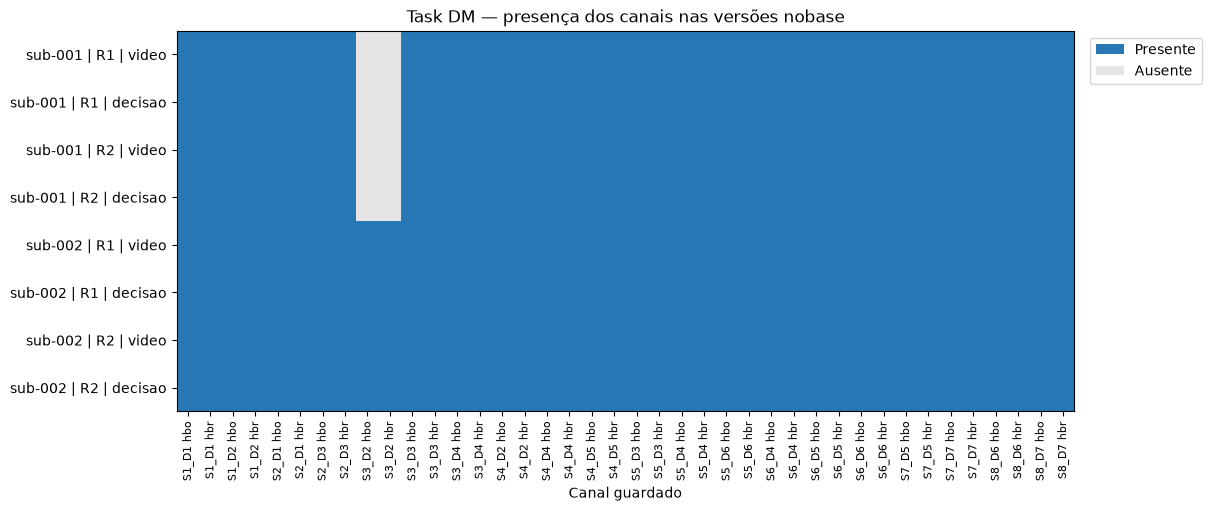


Nenhuma alteração aos objetos e nenhum ficheiro escrito.


In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import pandas as pd


if "epochs_edm3" not in globals():
    raise RuntimeError("Executa primeiro a Etapa E-DM.3.")

chaves_edm4 = [
    (sujeito, run, fase, "nobase")
    for sujeito in ["sub-001", "sub-002"]
    for run in [1, 2]
    for fase in ["video", "decisao"]
]

faltam_edm4 = [
    chave for chave in chaves_edm4
    if chave not in epochs_edm3
]
if faltam_edm4:
    raise RuntimeError(f"Objetos em falta: {faltam_edm4}")

metadata_edm4 = []
canais_edm4 = []

print("ETAPA E-DM.4 — METADADOS DAS VERSÕES NOBASE")

for chave in chaves_edm4:
    sujeito, run, fase, versao = chave
    ep = epochs_edm3[chave]

    print(f"\n{sujeito} | run {run} | {fase}")

    if ep.metadata is None:
        print("Sem metadata.")
    else:
        print(
            f"Linhas de metadata: {len(ep.metadata)} | "
            f"Épocas presentes: {len(ep.events)}"
        )
        print("Colunas completas:")

        for coluna in ep.metadata.columns:
            print(f"  - {coluna}")
            metadata_edm4.append({
                "sujeito": sujeito,
                "run": run,
                "fase": fase,
                "coluna": str(coluna),
                "dtype": str(ep.metadata[coluna].dtype),
            })

        print("\nPrimeiras três linhas:")
        print(ep.metadata.head(3).to_string(index=False))

    for nome, tipo in zip(ep.ch_names, ep.get_channel_types()):
        canais_edm4.append({
            "sujeito": sujeito,
            "run": run,
            "fase": fase,
            "canal": nome,
            "tipo": tipo,
            "objeto": f"{sujeito} | R{run} | {fase}",
        })


df_edm4_metadata_colunas = pd.DataFrame(
    metadata_edm4,
    columns=["sujeito", "run", "fase", "coluna", "dtype"],
)
df_edm4_canais = pd.DataFrame(canais_edm4)

comparacoes_edm4 = []

for sujeito in ["sub-001", "sub-002"]:
    for run in [1, 2]:
        video = epochs_edm3[
            (sujeito, run, "video", "nobase")
        ].ch_names
        decisao = epochs_edm3[
            (sujeito, run, "decisao", "nobase")
        ].ch_names

        comparacoes_edm4.append({
            "sujeito": sujeito,
            "run": run,
            "mesmos_canais_mesma_ordem": video == decisao,
            "apenas_video": "; ".join(
                sorted(set(video) - set(decisao))
            ),
            "apenas_decisao": "; ".join(
                sorted(set(decisao) - set(video))
            ),
        })

df_edm4_comparacao_fases = pd.DataFrame(comparacoes_edm4)

print("\nCOMPARAÇÃO DOS CANAIS ENTRE FASES")
print(df_edm4_comparacao_fases.to_string(index=False))

ordem_objetos_edm4 = [
    f"{sujeito} | R{run} | {fase}"
    for sujeito, run, fase, _ in chaves_edm4
]

matriz_edm4 = pd.crosstab(
    df_edm4_canais["objeto"],
    df_edm4_canais["canal"],
).reindex(index=ordem_objetos_edm4).gt(0).astype(int)

fig, ax = plt.subplots(
    figsize=(max(12, 0.3 * len(matriz_edm4.columns)), 5),
    constrained_layout=True,
)

ax.imshow(
    matriz_edm4.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap(["#e5e5e5", "#2878b5"]),
    vmin=0,
    vmax=1,
)

ax.set_xticks(
    range(len(matriz_edm4.columns)),
    matriz_edm4.columns,
    rotation=90,
    fontsize=8,
)
ax.set_yticks(
    range(len(matriz_edm4.index)),
    matriz_edm4.index,
)
ax.set_xlabel("Canal guardado")
ax.set_title("Task DM — presença dos canais nas versões nobase")

ax.legend(
    handles=[
        Patch(facecolor="#2878b5", label="Presente"),
        Patch(facecolor="#e5e5e5", label="Ausente"),
    ],
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
)

plt.show()

print("\nNenhuma alteração aos objetos e nenhum ficheiro escrito.")

## Etapa E-DM.5 — Correspondência das versões e primeiras curvas por canal

### Objetivo
Verificar a correspondência entre as versões `base` e `nobase`
e visualizar as primeiras curvas médias por canal da task
decision-making (DM).

### Entrada
- `epochs_edm3`: objetos de épocas do piloto.

### Procedimento
1. Comparar, entre versões de cada participante × run × fase:
   - Lista ordenada de canais.
   - Eventos.
   - Vetor temporal.
   - Metadados.
2. Confirmar as configurações de baseline registadas.
3. Carregar os valores das épocas através de cópias dos objetos.
4. Reconstruir a correção de baseline da versão `nobase`,
   subtraindo a média das amostras entre −1 e 0 s.
5. Comparar numericamente a reconstrução com a versão `base`.
6. Verificar a presença de valores não finitos.
7. Se todas as comparações forem compatíveis, calcular a média
   das épocas separadamente para cada canal da versão `base`.
8. Apresentar quatro figuras no output do notebook:
   uma por participante e run, com painéis separados por fase
   e cromóforo.

### Saídas
- `df_edm5_verificacao`: comparações entre versões.
- `medias_edm5`: curvas médias por canal, em unidades nativas,
  indexadas por participante, run e fase.
- Quatro figuras com as curvas apresentadas em µmol/L.

### Critério numérico
A comparação da baseline usa `rtol=1e-5` e `atol=1e-12`
nas unidades nativas. Esta tolerância verifica compatibilidade
numérica, não qualidade fisiológica.

### Limites
- Os gráficos usam a baseline já guardada; não escolhem nem validam
  a adequação fisiológica dessa baseline.
- As linhas representam médias das épocas por canal, não ensaios
  individuais, regiões de interesse ou participantes adicionais.
- A janela alinhada à decisão pode incluir fases posteriores.
- Não se interpreta a curva alinhada à decisão como um efeito
  isolado da observação prévia do vídeo.
- Não se rejeitam épocas ou canais.
- Não se combinam runs nem participantes.
- Os objetos originais são preservados.
- Não se escrevem ficheiros.

Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
Loading data for 10 events and 113 original time points ...
ETAPA E-DM.5 — CORRESPONDÊNCIA ENTRE VER

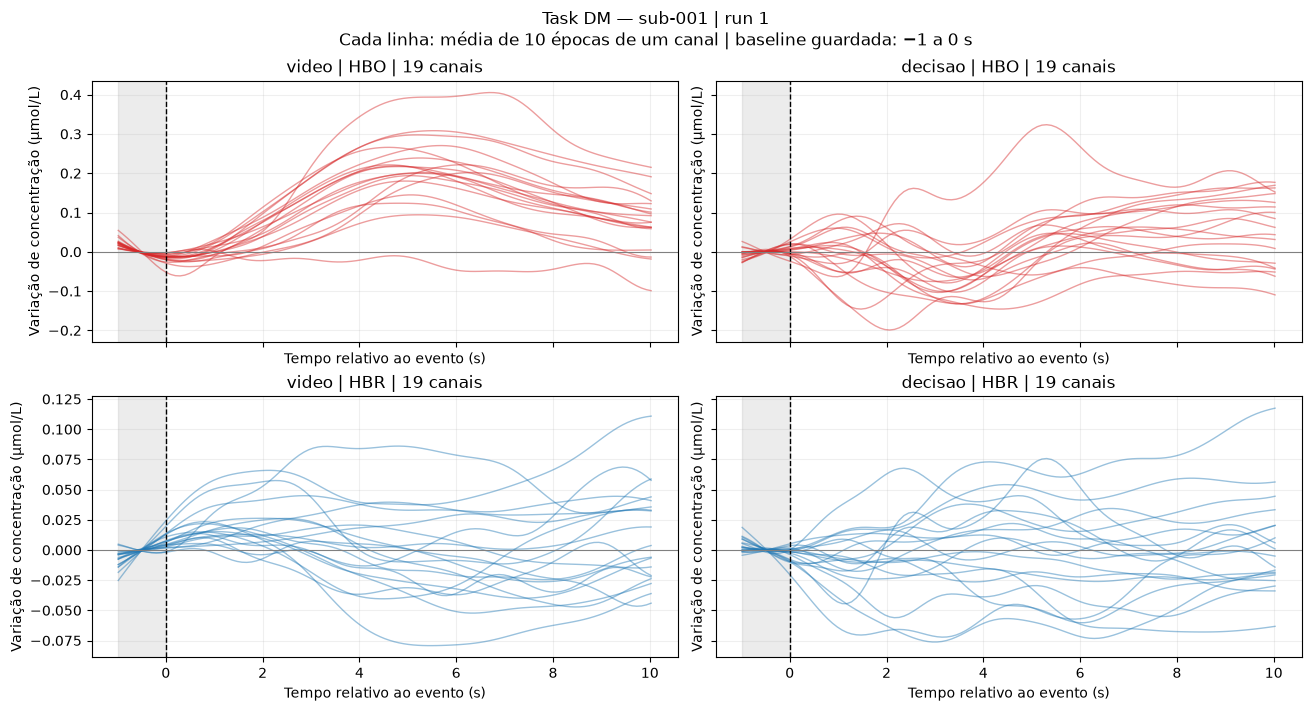

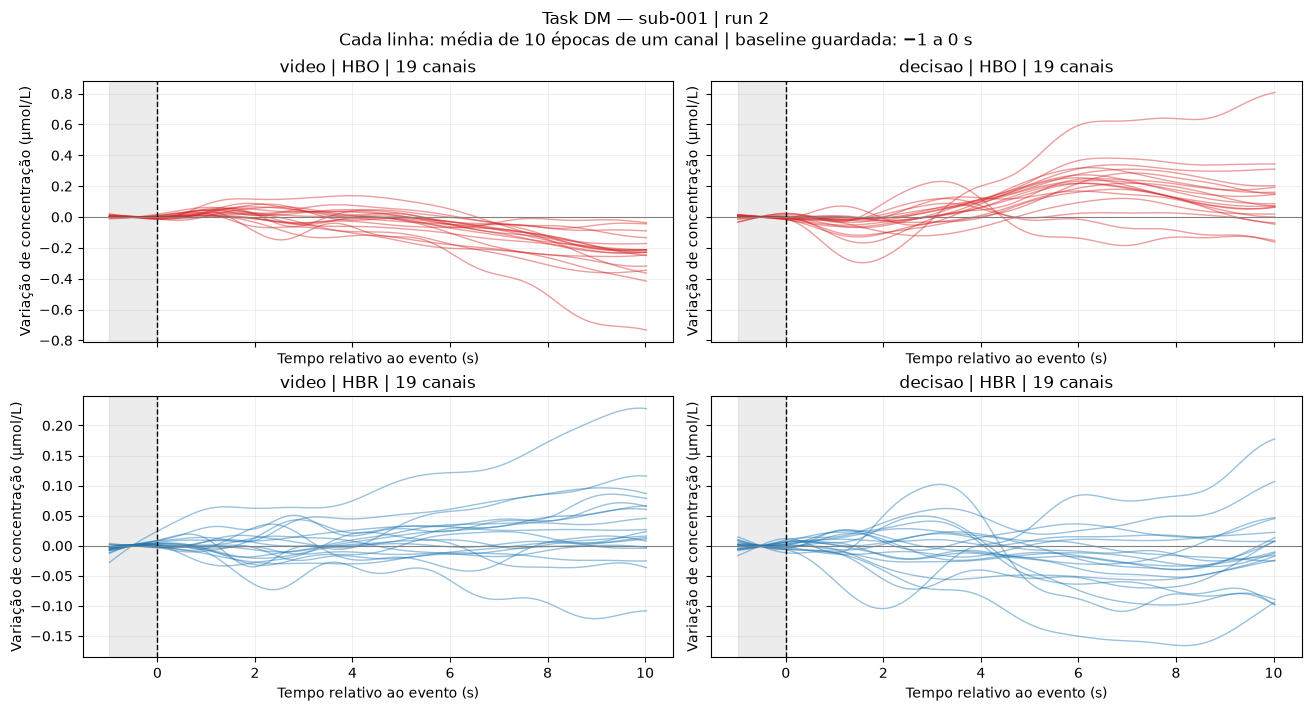

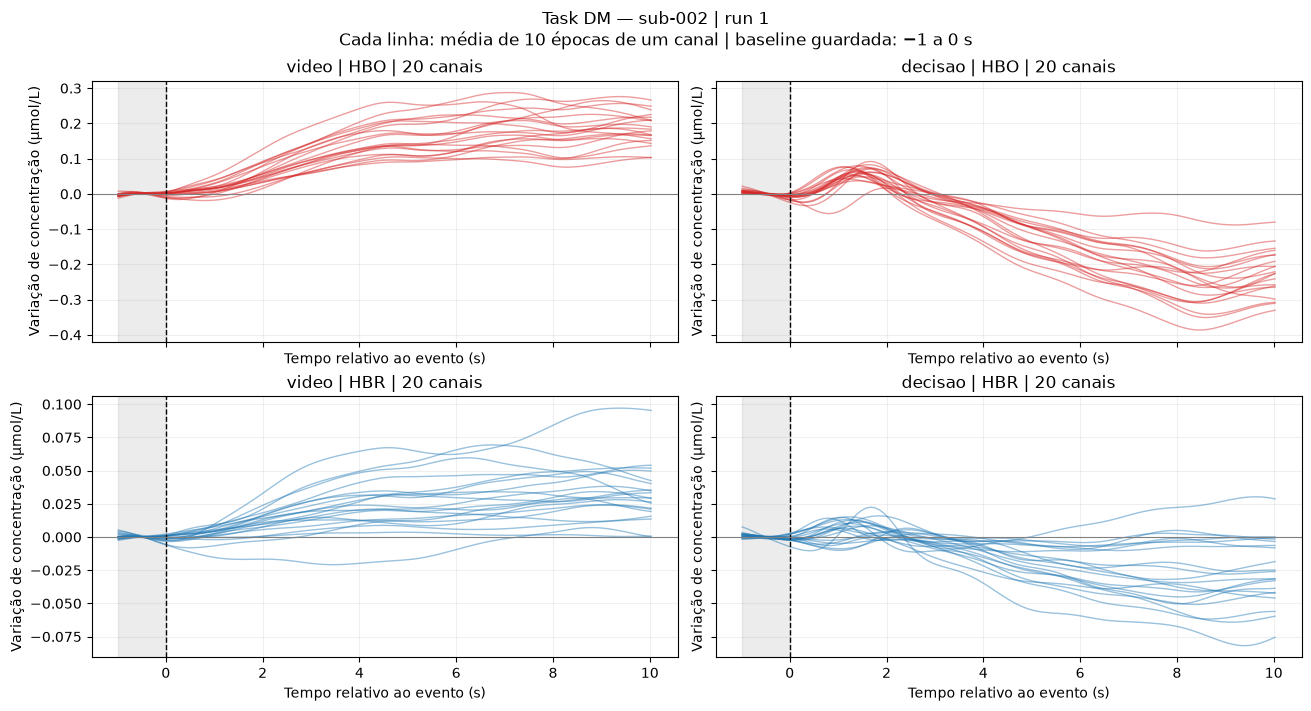

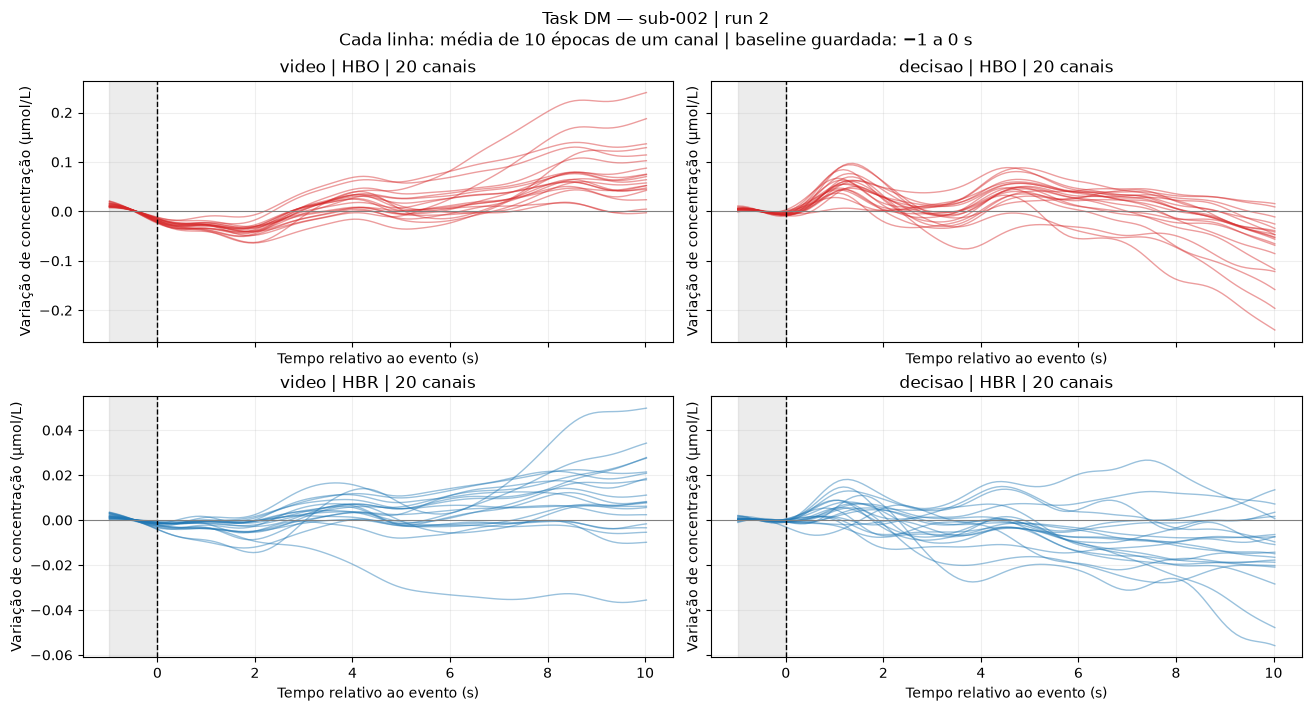


Nenhuma rejeição aplicada e nenhum ficheiro escrito.
Objetos originais preservados.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


if "epochs_edm3" not in globals():
    raise RuntimeError("Executa primeiro a Etapa E-DM.3.")

verificacoes_edm5 = []
medias_edm5 = {}

for sujeito in ["sub-001", "sub-002"]:
    for run in [1, 2]:
        for fase in ["video", "decisao"]:
            chave = (sujeito, run, fase)

            for versao in ["base", "nobase"]:
                if (*chave, versao) not in epochs_edm3:
                    raise RuntimeError(
                        f"Objeto em falta: {(*chave, versao)}"
                    )

            base = epochs_edm3[(*chave, "base")]
            nobase = epochs_edm3[(*chave, "nobase")]

            mesmos_tempos = np.array_equal(base.times, nobase.times)
            mesmos_canais = base.ch_names == nobase.ch_names
            mesmos_eventos = np.array_equal(base.events, nobase.events)

            if base.metadata is None or nobase.metadata is None:
                mesmos_metadata = (
                    base.metadata is None and nobase.metadata is None
                )
            else:
                mesmos_metadata = base.metadata.equals(nobase.metadata)

            baseline_config_ok = (
                base.baseline is not None
                and np.allclose(base.baseline, [-1.0, 0.0])
                and nobase.baseline is None
            )

            linha = {
                "sujeito": sujeito,
                "run": run,
                "fase": fase,
                "mesmos_canais": mesmos_canais,
                "mesmos_eventos": mesmos_eventos,
                "mesmos_tempos": mesmos_tempos,
                "mesmos_metadata": mesmos_metadata,
                "baseline_config_ok": baseline_config_ok,
                "valores_finitos": False,
                "erro_max_baseline_nativo": np.nan,
                "baseline_compativel": False,
            }

            estrutura_ok = all([
                mesmos_canais, mesmos_eventos, mesmos_tempos,
                mesmos_metadata, baseline_config_ok,
            ])

            if estrutura_ok:
                dados_base = base.copy().get_data()
                dados_nobase = nobase.copy().get_data()

                finitos = (
                    np.isfinite(dados_base).all()
                    and np.isfinite(dados_nobase).all()
                )
                linha["valores_finitos"] = bool(finitos)

                mascara = (
                    (nobase.times >= -1.0 - 1e-12)
                    & (nobase.times <= 0.0 + 1e-12)
                )

                if finitos and mascara.any():
                    reconstruidos = (
                        dados_nobase
                        - dados_nobase[:, :, mascara].mean(
                            axis=-1, keepdims=True
                        )
                    )

                    linha["erro_max_baseline_nativo"] = float(
                        np.max(np.abs(dados_base - reconstruidos))
                    )
                    linha["baseline_compativel"] = bool(
                        np.allclose(
                            dados_base, reconstruidos,
                            rtol=1e-5, atol=1e-12,
                        )
                    )

                    if linha["baseline_compativel"]:
                        medias_edm5[chave] = {
                            "tempos_s": base.times.copy(),
                            "canais": list(base.ch_names),
                            "tipos": base.get_channel_types(),
                            "media": dados_base.mean(axis=0),
                            "n_epochs": len(base.events),
                        }

            verificacoes_edm5.append(linha)


df_edm5_verificacao = pd.DataFrame(verificacoes_edm5)

print("ETAPA E-DM.5 — CORRESPONDÊNCIA ENTRE VERSÕES")
print(df_edm5_verificacao.to_string(index=False))

pronto_edm5 = (
    len(df_edm5_verificacao) == 8
    and df_edm5_verificacao["baseline_compativel"].all()
)

if not pronto_edm5:
    print(
        "\nHá diferenças a investigar. "
        "As curvas não foram desenhadas."
    )
else:
    for sujeito in ["sub-001", "sub-002"]:
        for run in [1, 2]:
            fig, eixos = plt.subplots(
                2, 2, figsize=(13, 7),
                sharex=True, sharey="row",
                constrained_layout=True,
            )

            for coluna, fase in enumerate(["video", "decisao"]):
                resultado = medias_edm5[(sujeito, run, fase)]
                tempos = resultado["tempos_s"]

                for linha, (tipo, cor) in enumerate([
                    ("hbo", "tab:red"),
                    ("hbr", "tab:blue"),
                ]):
                    ax = eixos[linha, coluna]
                    indices = [
                        i for i, t in enumerate(resultado["tipos"])
                        if t == tipo
                    ]

                    for i in indices:
                        ax.plot(
                            tempos,
                            resultado["media"][i] * 1e6,
                            color=cor,
                            alpha=0.45,
                            linewidth=1,
                        )

                    ax.axvspan(
                        max(-1.0, tempos[0]), 0,
                        color="grey", alpha=0.15,
                    )
                    ax.axvline(0, color="black", linestyle="--", lw=1)
                    ax.axhline(0, color="grey", linewidth=0.8)
                    ax.set_title(
                        f"{fase} | {tipo.upper()} | "
                        f"{len(indices)} canais"
                    )
                    ax.set_xlabel("Tempo relativo ao evento (s)")
                    ax.set_ylabel("Variação de concentração (µmol/L)")
                    ax.grid(alpha=0.2)

            fig.suptitle(
                f"Task DM — {sujeito} | run {run}\n"
                "Cada linha: média de 10 épocas de um canal | "
                "baseline guardada: −1 a 0 s"
            )
            plt.show()

print("\nNenhuma rejeição aplicada e nenhum ficheiro escrito.")
print("Objetos originais preservados.")

## Etapa E-DM.6 — Contexto temporal das janelas de épocas

### Objetivo
Identificar as fases temporais abrangidas pelas épocas da task
decision-making (DM), com especial atenção à janela alinhada
ao início da decisão.

### Entrada
- `epochs_edm3`: objetos de épocas com metadados temporais.

### Procedimento
1. Usar os metadados das versões `nobase` alinhadas à decisão,
   sem duplicar os ensaios entre fases ou versões.
2. Confirmar a existência e a ordem temporal dos onsets:
   vídeo, decisão, fixação pós-resposta e fase seguinte.
3. Calcular, por ensaio:
   - Intervalo entre início do vídeo e início da decisão.
   - Intervalo entre decisão e fixação pós-resposta.
   - Intervalo entre decisão e início da fase seguinte.
4. Comparar esses intervalos com os limites das épocas guardadas.
5. Resumir os resultados por participante e run.
6. Mostrar uma figura com quatro painéis, representando a sequência
   de fases dentro da janela alinhada à decisão, ensaio a ensaio.

### Saídas
- `df_edm6_tempos`: intervalos e indicadores por ensaio.
- `df_edm6_resumo`: resumo por participante e run.
- Figura temporal apresentada no output do notebook.

### Limites
- Os onsets são usados tal como estão guardados nos metadados.
- Esta etapa não valida o alinhamento com o relógio PsychoPy.
- O intervalo entre os códigos `130` e `150` não é automaticamente
  interpretado como tempo de reação comportamental.
- A região após o início da fase seguinte não é decomposta
  em outros eventos nesta figura.
- A baseline pré-decisão é representada temporalmente, mas a sua
  adequação fisiológica não é validada nesta etapa.
- Não se alteram épocas, não se juntam runs e não se extraem
  métricas de amplitude do sinal.
- Não se escrevem ficheiros.

ETAPA E-DM.6 — CONTEXTO TEMPORAL
sujeito  run  n_ensaios  video_min_s  video_max_s  intervalo_130_150_min_s  intervalo_130_150_max_s  n_decisao_na_janela_video  n_fixpos_na_janela_decisao  n_fase_seguinte_na_janela_decisao
sub-001    1         10       15.681       29.693                    0.618                    2.813                          0                          10                                 10
sub-001    2         10       17.414       23.722                    1.094                    2.279                          0                          10                                 10
sub-002    1         10       15.656       29.617                    0.917                    3.108                          0                          10                                 10
sub-002    2         10       17.432       23.672                    0.359                    1.590                          0                          10                                 10


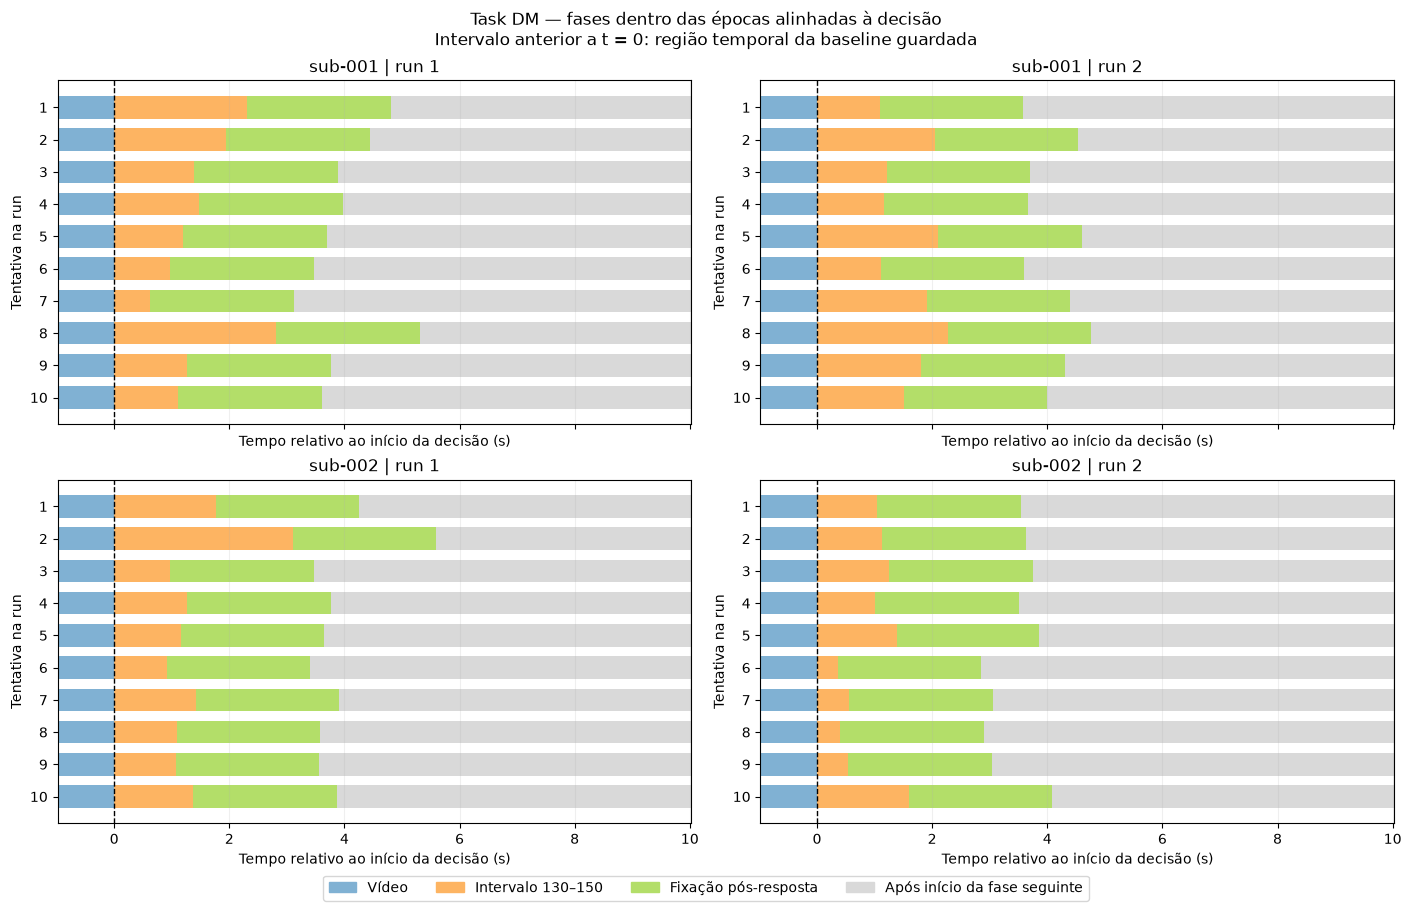


Nenhuma época alterada e nenhum ficheiro escrito.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


if "epochs_edm3" not in globals():
    raise RuntimeError("Executa primeiro a Etapa E-DM.3.")

colunas_edm6 = [
    "tentativa_na_run",
    "onset_video_s",
    "onset_decisao_s",
    "onset_fixacao_pos_s",
    "onset_fase_seguinte_s",
]

blocos_edm6 = []

for sujeito in ["sub-001", "sub-002"]:
    for run in [1, 2]:
        ep_dec = epochs_edm3[(sujeito, run, "decisao", "nobase")]
        ep_vid = epochs_edm3[(sujeito, run, "video", "nobase")]

        if ep_dec.metadata is None:
            raise RuntimeError(f"Sem metadata: {sujeito}, run {run}")

        faltam = set(colunas_edm6) - set(ep_dec.metadata.columns)
        if faltam:
            raise RuntimeError(f"Colunas em falta: {sorted(faltam)}")

        md = ep_dec.metadata[colunas_edm6].copy().reset_index(drop=True)

        if md["tentativa_na_run"].duplicated().any():
            raise RuntimeError(
                f"Tentativas duplicadas: {sujeito}, run {run}"
            )

        onsets = md[colunas_edm6[1:]].to_numpy(dtype=float)

        if not np.isfinite(onsets).all():
            raise RuntimeError(
                f"Onsets não finitos: {sujeito}, run {run}"
            )

        if (np.diff(onsets, axis=1) < 0).any():
            raise RuntimeError(
                f"Ordem temporal inesperada: {sujeito}, run {run}"
            )

        md["sujeito"] = sujeito
        md["run"] = run
        md["video_ate_decisao_s"] = (
            md["onset_decisao_s"] - md["onset_video_s"]
        )
        md["decisao_ate_fixpos_s"] = (
            md["onset_fixacao_pos_s"] - md["onset_decisao_s"]
        )
        md["decisao_ate_fase_seguinte_s"] = (
            md["onset_fase_seguinte_s"] - md["onset_decisao_s"]
        )
        md["decisao_dentro_janela_video"] = (
            md["video_ate_decisao_s"] <= ep_vid.tmax
        )
        md["fixpos_dentro_janela_decisao"] = (
            md["decisao_ate_fixpos_s"] <= ep_dec.tmax
        )
        md["fase_seguinte_dentro_janela_decisao"] = (
            md["decisao_ate_fase_seguinte_s"] <= ep_dec.tmax
        )

        blocos_edm6.append(md)

df_edm6_tempos = pd.concat(blocos_edm6, ignore_index=True)

df_edm6_resumo = df_edm6_tempos.groupby(
    ["sujeito", "run"], as_index=False
).agg(
    n_ensaios=("tentativa_na_run", "size"),
    video_min_s=("video_ate_decisao_s", "min"),
    video_max_s=("video_ate_decisao_s", "max"),
    intervalo_130_150_min_s=("decisao_ate_fixpos_s", "min"),
    intervalo_130_150_max_s=("decisao_ate_fixpos_s", "max"),
    n_decisao_na_janela_video=(
        "decisao_dentro_janela_video", "sum"
    ),
    n_fixpos_na_janela_decisao=(
        "fixpos_dentro_janela_decisao", "sum"
    ),
    n_fase_seguinte_na_janela_decisao=(
        "fase_seguinte_dentro_janela_decisao", "sum"
    ),
)

print("ETAPA E-DM.6 — CONTEXTO TEMPORAL")
print(
    df_edm6_resumo.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}",
    )
)

cores_edm6 = {
    "video": "#80b1d3",
    "decisao": "#fdb462",
    "fixpos": "#b3de69",
    "seguinte": "#d9d9d9",
}

fig, eixos = plt.subplots(
    2, 2, figsize=(14, 9),
    sharex=True, constrained_layout=True,
)

for i, sujeito in enumerate(["sub-001", "sub-002"]):
    for j, run in enumerate([1, 2]):
        ax = eixos[i, j]
        ep = epochs_edm3[(sujeito, run, "decisao", "nobase")]
        bloco = df_edm6_tempos.loc[
            df_edm6_tempos["sujeito"].eq(sujeito)
            & df_edm6_tempos["run"].eq(run)
        ].sort_values("tentativa_na_run")

        for y, r in enumerate(bloco.itertuples(index=False)):
            segmentos = [
                (-r.video_ate_decisao_s, 0, "video"),
                (0, r.decisao_ate_fixpos_s, "decisao"),
                (
                    r.decisao_ate_fixpos_s,
                    r.decisao_ate_fase_seguinte_s,
                    "fixpos",
                ),
                (
                    r.decisao_ate_fase_seguinte_s,
                    ep.tmax,
                    "seguinte",
                ),
            ]

            for inicio, fim, fase in segmentos:
                inicio = max(inicio, ep.tmin)
                fim = min(fim, ep.tmax)
                if fim > inicio:
                    ax.broken_barh(
                        [(inicio, fim - inicio)],
                        (y - 0.35, 0.7),
                        facecolors=cores_edm6[fase],
                    )

        ax.axvline(0, color="black", linestyle="--", lw=1)
        ax.set_xlim(ep.tmin, ep.tmax)
        ax.set_yticks(
            range(len(bloco)),
            bloco["tentativa_na_run"].astype(str),
        )
        ax.invert_yaxis()
        ax.set_title(f"{sujeito} | run {run}")
        ax.set_ylabel("Tentativa na run")
        ax.set_xlabel("Tempo relativo ao início da decisão (s)")
        ax.grid(axis="x", alpha=0.2)

fig.legend(
    handles=[
        Patch(color=cores_edm6["video"], label="Vídeo"),
        Patch(color=cores_edm6["decisao"], label="Intervalo 130–150"),
        Patch(color=cores_edm6["fixpos"], label="Fixação pós-resposta"),
        Patch(
            color=cores_edm6["seguinte"],
            label="Após início da fase seguinte",
        ),
    ],
    loc="outside lower center",
    ncol=4,
)

fig.suptitle(
    "Task DM — fases dentro das épocas alinhadas à decisão\n"
    "Intervalo anterior a t = 0: região temporal da baseline guardada"
)
plt.show()

print("\nNenhuma época alterada e nenhum ficheiro escrito.")

## Etapa E-DM.7 — Inspeção dos ensaios individuais por canal

### Objetivo
Comparar as curvas dos ensaios individuais com a respetiva média,
em cada canal da task decision-making (DM).

### Entradas
- `epochs_edm3`: objetos de épocas.
- `df_edm5_verificacao`: correspondência entre versões verificada
  na Etapa E-DM.5.
- Seleção explícita de participante, run e fase.

### Configuração inicial
- Participante: `sub-001`.
- Run: 1.
- Fase de alinhamento: `video`.
- Versão: `base`.

### Procedimento
1. Confirmar que a combinação selecionada passou a verificação
   de correspondência entre versões.
2. Carregar os dados através de uma cópia do objeto.
3. Confirmar que os valores são finitos.
4. Mostrar todos os canais HbO numa figura e todos os canais HbR
   noutra figura.
5. Em cada painel, representar:
   - Cada ensaio com uma linha fina.
   - A média dos ensaios com uma linha mais espessa.
   - O instante de alinhamento e a região de baseline.
6. Usar a mesma escala vertical nos painéis de cada figura.

### Saída
- Duas figuras no output do notebook, uma por cromóforo.

### Limites
- A inspeção é descritiva e não aplica rejeições automáticas.
- Uma curva diferente das restantes não é automaticamente um artefacto.
- As linhas finas representam ensaios do mesmo participante,
  não participantes independentes.
- A média não é acompanhada de um teste de significância.
- Não se escolhem canais pela amplitude ou pelo sinal da resposta.
- A baseline já guardada é mantida.
- As limitações temporais identificadas na Etapa E-DM.6 continuam
  aplicáveis.
- Não se alteram os objetos originais nem se escrevem ficheiros.

Loading data for 10 events and 113 original time points ...
ETAPA E-DM.7 — sub-001 | run 1 | video | base
Épocas presentes: 10


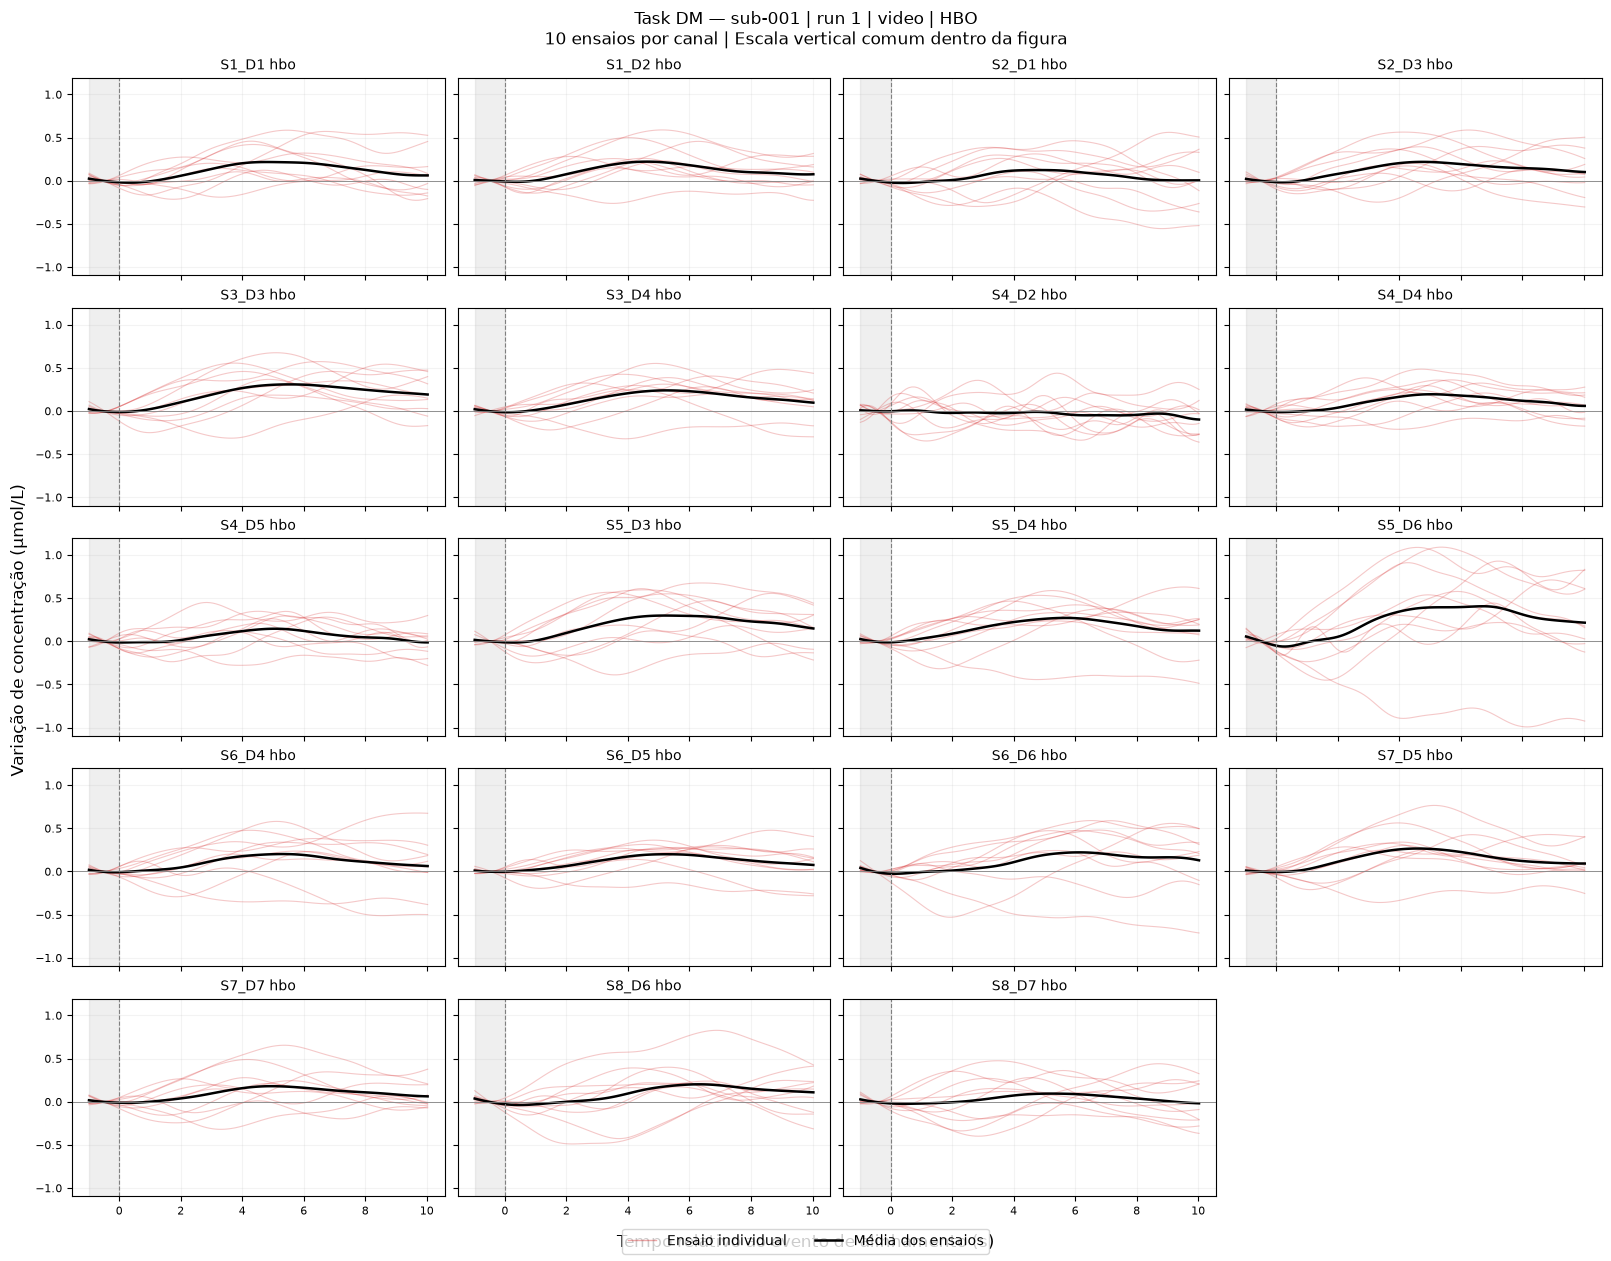

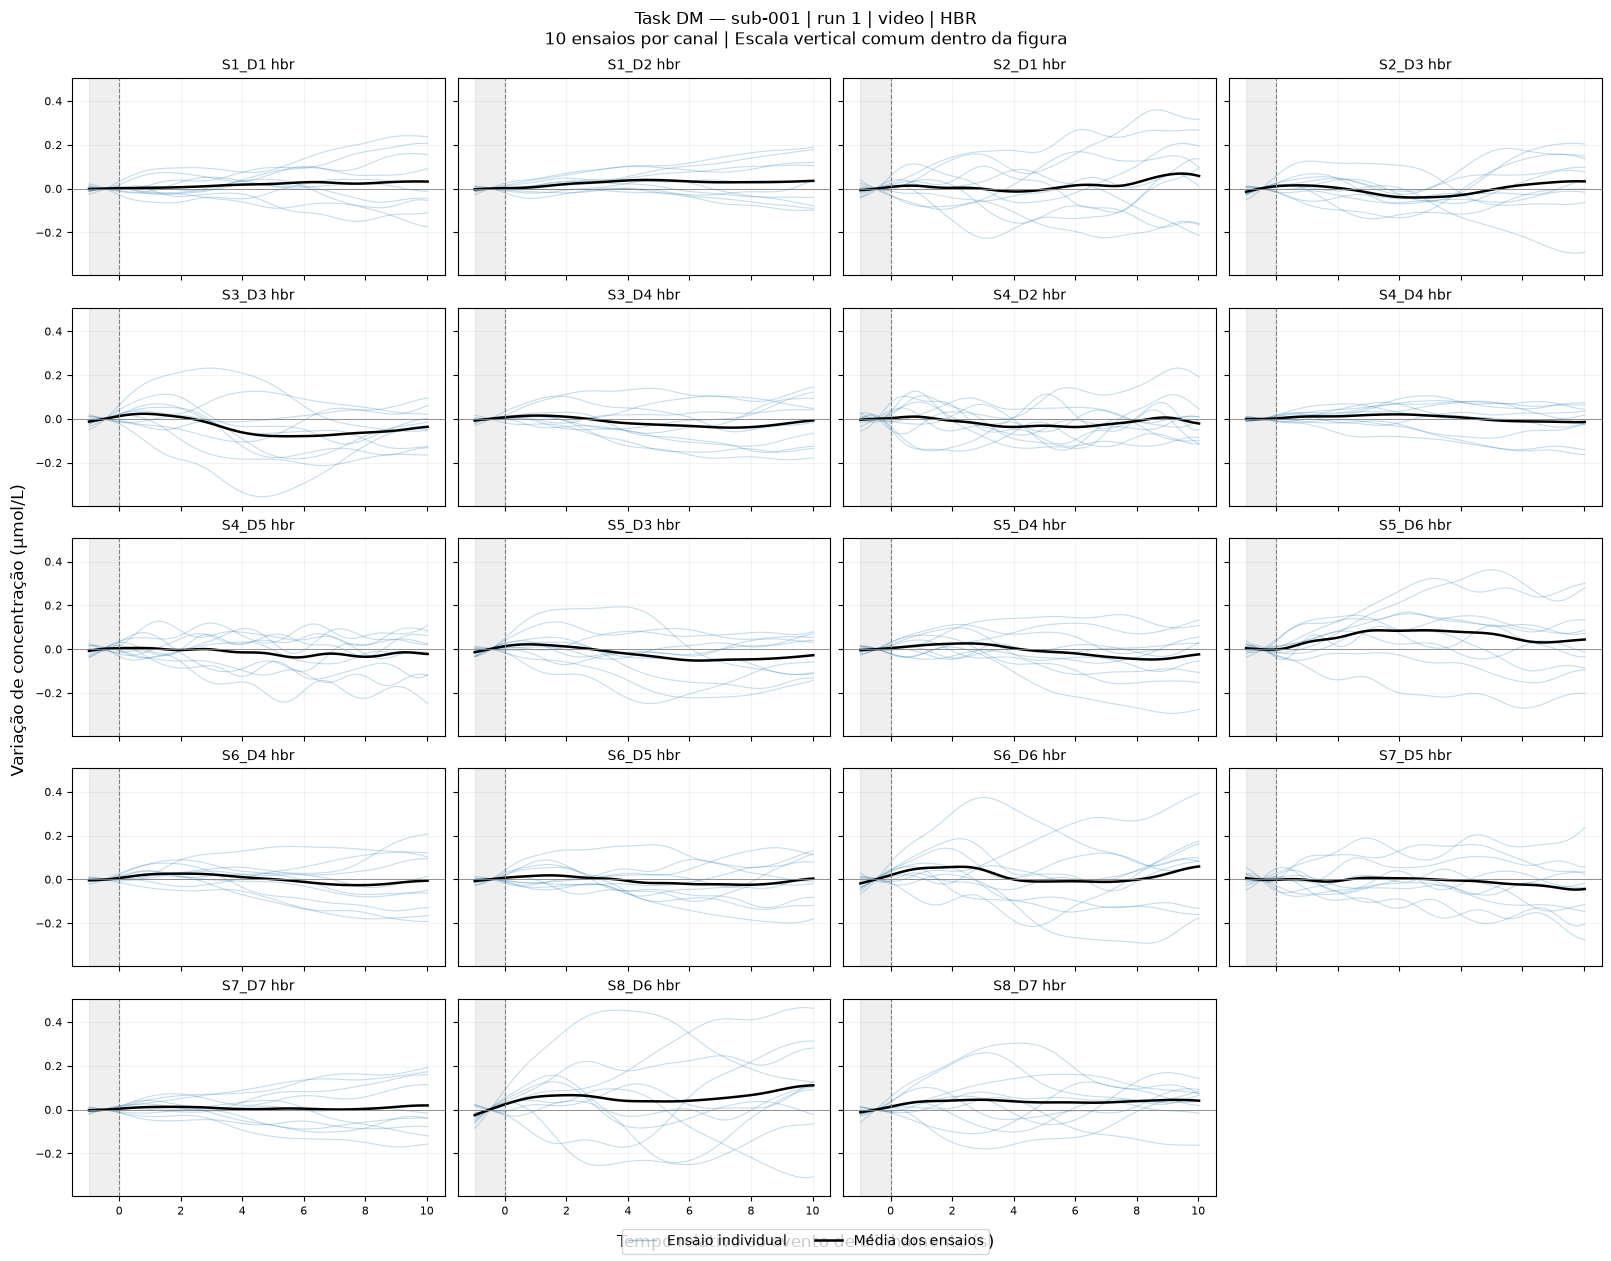


Nenhuma época ou canal rejeitado.
Objetos originais preservados e nenhum ficheiro escrito.


In [8]:
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


for nome in ["epochs_edm3", "df_edm5_verificacao"]:
    if nome not in globals():
        raise RuntimeError(f"Variável em falta: {nome}")

sujeito_edm7 = "sub-001"
run_edm7 = 1
fase_edm7 = "video"
versao_edm7 = "base"

chave_edm7 = (
    sujeito_edm7, run_edm7, fase_edm7, versao_edm7
)

if chave_edm7 not in epochs_edm3:
    raise RuntimeError(f"Objeto não encontrado: {chave_edm7}")

verificacao_edm7 = df_edm5_verificacao.loc[
    df_edm5_verificacao["sujeito"].eq(sujeito_edm7)
    & df_edm5_verificacao["run"].eq(run_edm7)
    & df_edm5_verificacao["fase"].eq(fase_edm7)
]

if (
    len(verificacao_edm7) != 1
    or not verificacao_edm7["baseline_compativel"].all()
):
    raise RuntimeError(
        "Esta combinação não tem correspondência de baseline confirmada."
    )

ep_edm7 = epochs_edm3[chave_edm7]
dados_edm7 = ep_edm7.copy().get_data() * 1e6
tempos_edm7 = ep_edm7.times
tipos_edm7 = ep_edm7.get_channel_types()

if not np.isfinite(dados_edm7).all():
    raise RuntimeError("Foram encontrados valores não finitos.")

print(
    f"ETAPA E-DM.7 — {sujeito_edm7} | run {run_edm7} | "
    f"{fase_edm7} | {versao_edm7}"
)
print(f"Épocas presentes: {len(dados_edm7)}")

for tipo, cor in [("hbo", "tab:red"), ("hbr", "tab:blue")]:
    indices = [
        i for i, t in enumerate(tipos_edm7) if t == tipo
    ]

    if not indices:
        print(f"Sem canais {tipo}.")
        continue

    n_colunas = 4
    n_linhas = math.ceil(len(indices) / n_colunas)

    fig, eixos = plt.subplots(
        n_linhas,
        n_colunas,
        figsize=(16, 2.5 * n_linhas),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, indice in zip(eixos.flat, indices):
        ensaios = dados_edm7[:, indice, :]

        ax.plot(
            tempos_edm7,
            ensaios.T,
            color=cor,
            alpha=0.25,
            linewidth=0.8,
        )
        ax.plot(
            tempos_edm7,
            ensaios.mean(axis=0),
            color="black",
            linewidth=1.8,
        )

        if ep_edm7.baseline is not None:
            inicio, fim = ep_edm7.baseline
            inicio = ep_edm7.tmin if inicio is None else inicio
            fim = ep_edm7.tmax if fim is None else fim
            ax.axvspan(
                max(inicio, ep_edm7.tmin),
                min(fim, ep_edm7.tmax),
                color="grey",
                alpha=0.12,
            )

        ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="grey", linewidth=0.6)
        ax.set_title(ep_edm7.ch_names[indice], fontsize=10)
        ax.grid(alpha=0.15)
        ax.tick_params(labelsize=8)

    for ax in list(eixos.flat)[len(indices):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Task DM — {sujeito_edm7} | run {run_edm7} | "
        f"{fase_edm7} | {tipo.upper()}\n"
        f"{len(dados_edm7)} ensaios por canal | "
        "Escala vertical comum dentro da figura"
    )
    fig.supxlabel("Tempo relativo ao evento de alinhamento (s)")
    fig.supylabel("Variação de concentração (µmol/L)")

    fig.legend(
        handles=[
            Line2D(
                [0], [0], color=cor, alpha=0.4,
                linewidth=1, label="Ensaio individual",
            ),
            Line2D(
                [0], [0], color="black",
                linewidth=1.8, label="Média dos ensaios",
            ),
        ],
        loc="outside lower center",
        ncol=2,
    )

    plt.show()

print("\nNenhuma época ou canal rejeitado.")
print("Objetos originais preservados e nenhum ficheiro escrito.")

### Etapa E-DM.7 — Continuação: sub-001, run 1, decisão

#### Objetivo
Inspecionar os ensaios individuais por canal nas épocas alinhadas
à decisão, mantendo o participante, a run e o procedimento usados
na inspeção do alinhamento ao vídeo.

#### Configuração
- Participante: `sub-001`.
- Run: 1.
- Fase de alinhamento: `decisao`.
- Versão: `base`.

#### Visualização
- Uma figura para HbO e outra para HbR.
- Linhas finas: ensaios individuais.
- Linha preta: média dos ensaios.
- Escala vertical comum aos canais dentro de cada figura.

#### Limites
- Os limites verticais são calculados para cada figura; não se
  presume que sejam iguais aos das figuras anteriores.
- A baseline pré-decisão está temporalmente no vídeo anterior.
- A janela inclui o intervalo 130–150, a fixação pós-resposta
  e tempo após o início da fase seguinte.
- As curvas não representam um efeito isolado da decisão.
- Não se rejeitam épocas ou canais e não se escrevem ficheiros.

Loading data for 10 events and 113 original time points ...
ETAPA E-DM.7 — sub-001 | run 1 | decisao | base
Épocas presentes: 10


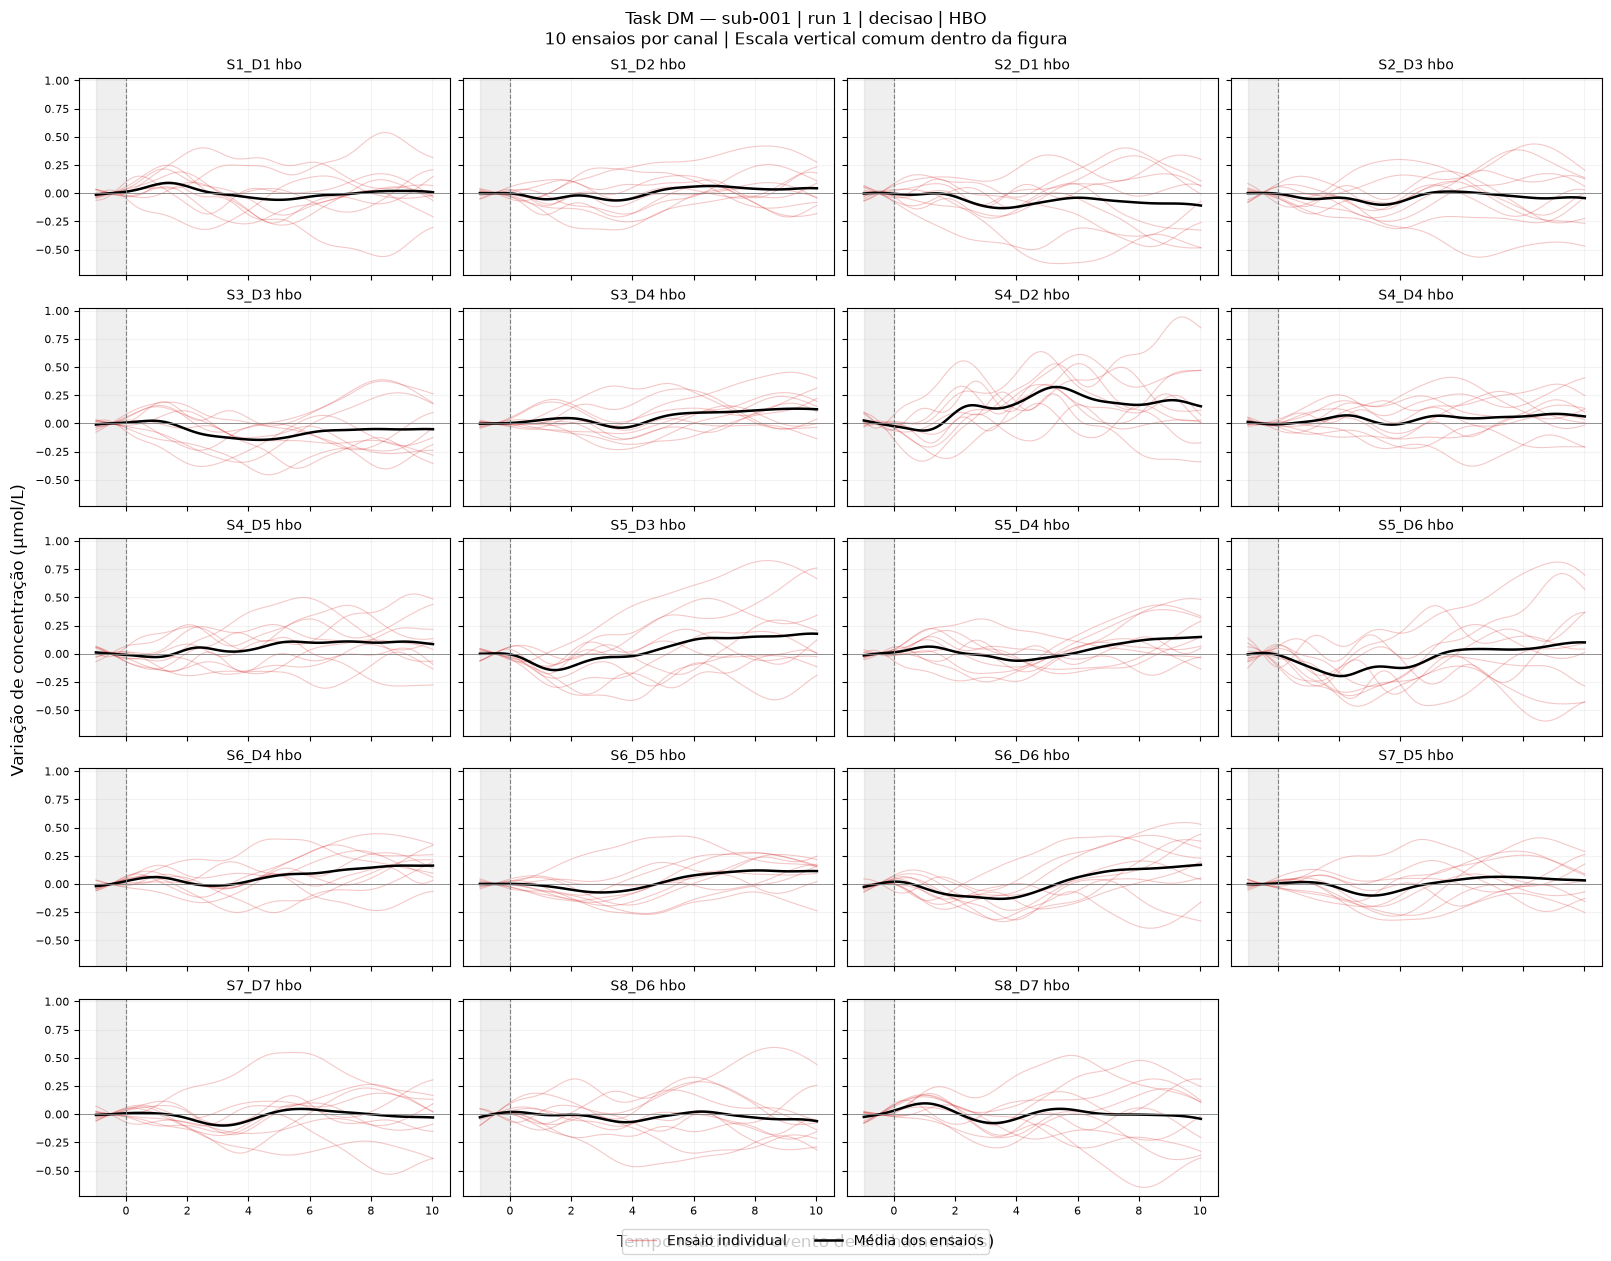

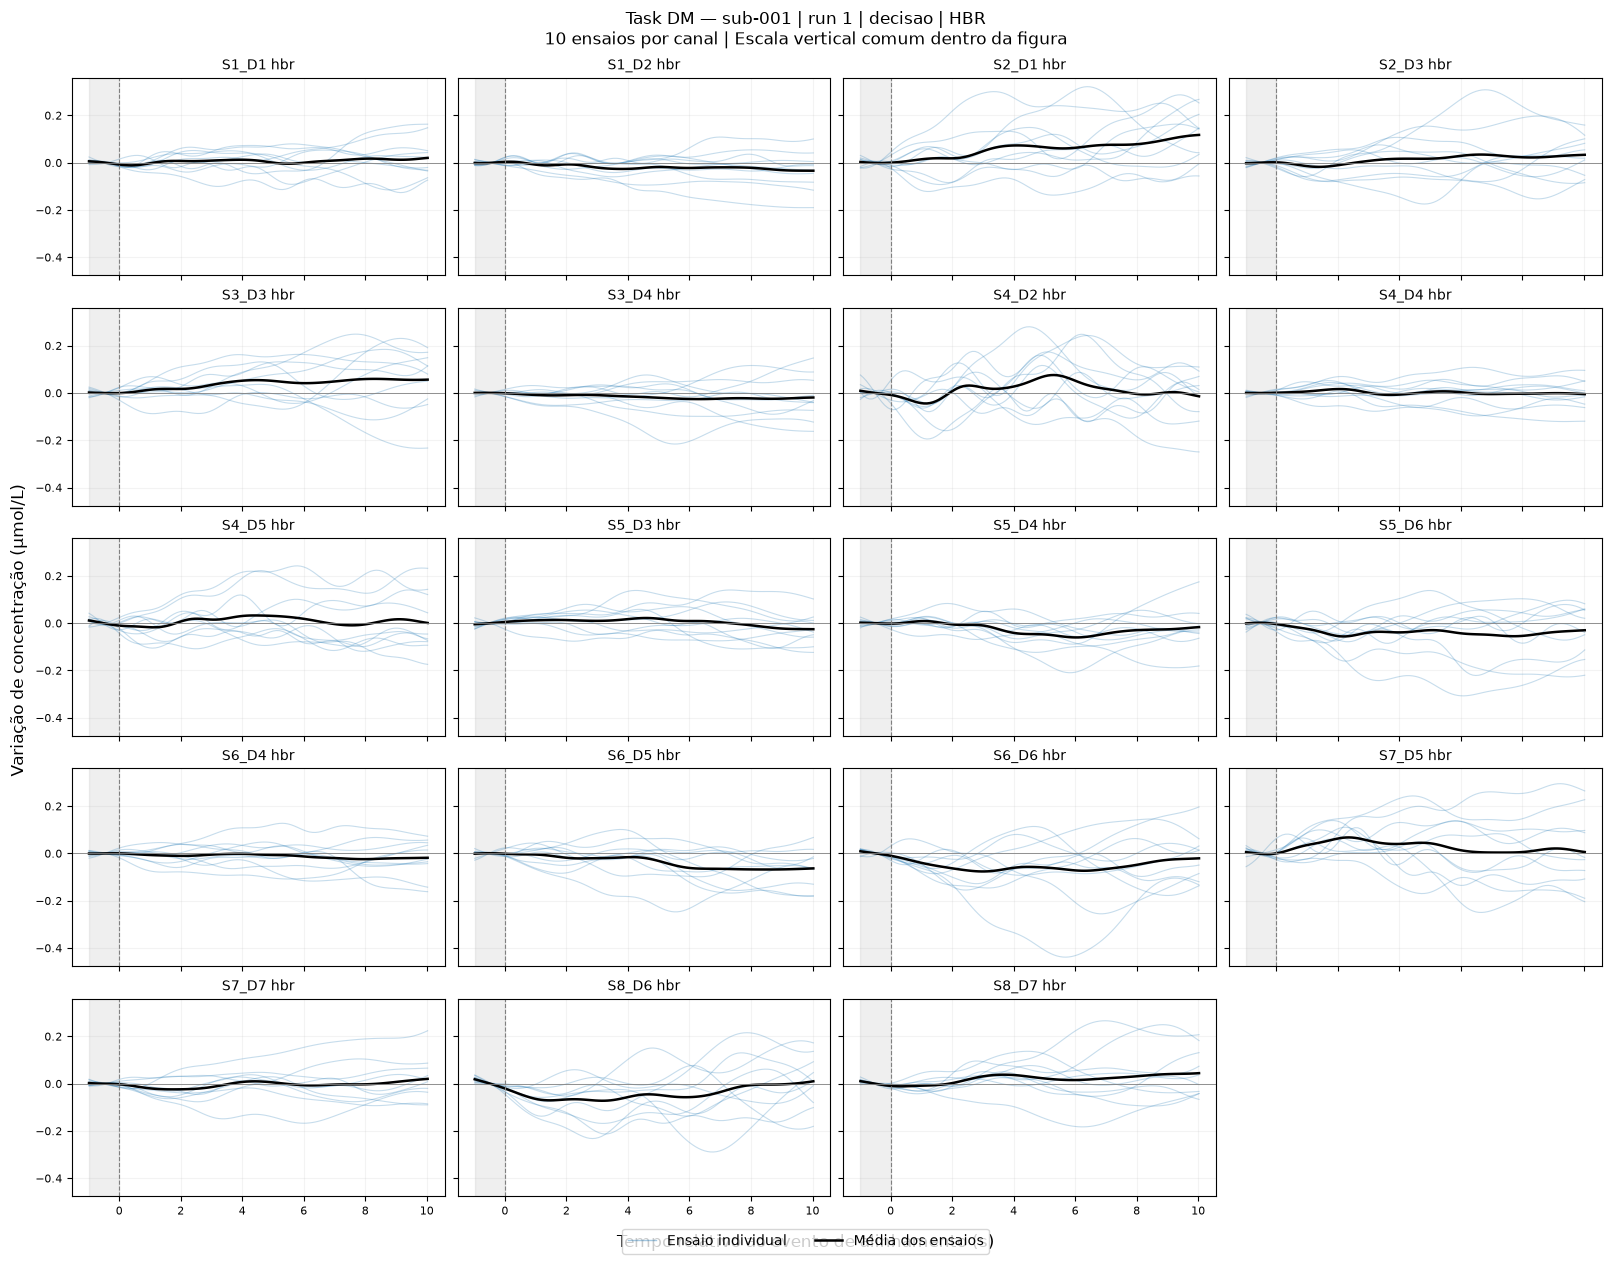


Nenhuma época ou canal rejeitado.
Objetos originais preservados e nenhum ficheiro escrito.


In [9]:
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


for nome in ["epochs_edm3", "df_edm5_verificacao"]:
    if nome not in globals():
        raise RuntimeError(f"Variável em falta: {nome}")

sujeito_edm7 = "sub-001"
run_edm7 = 1
fase_edm7 = "decisao"
versao_edm7 = "base"

chave_edm7 = (
    sujeito_edm7, run_edm7, fase_edm7, versao_edm7
)

if chave_edm7 not in epochs_edm3:
    raise RuntimeError(f"Objeto não encontrado: {chave_edm7}")

verificacao_edm7 = df_edm5_verificacao.loc[
    df_edm5_verificacao["sujeito"].eq(sujeito_edm7)
    & df_edm5_verificacao["run"].eq(run_edm7)
    & df_edm5_verificacao["fase"].eq(fase_edm7)
]

if (
    len(verificacao_edm7) != 1
    or not verificacao_edm7["baseline_compativel"].all()
):
    raise RuntimeError(
        "Esta combinação não tem correspondência de baseline confirmada."
    )

ep_edm7 = epochs_edm3[chave_edm7]
dados_edm7 = ep_edm7.copy().get_data() * 1e6
tempos_edm7 = ep_edm7.times
tipos_edm7 = ep_edm7.get_channel_types()

if not np.isfinite(dados_edm7).all():
    raise RuntimeError("Foram encontrados valores não finitos.")

print(
    f"ETAPA E-DM.7 — {sujeito_edm7} | run {run_edm7} | "
    f"{fase_edm7} | {versao_edm7}"
)
print(f"Épocas presentes: {len(dados_edm7)}")

for tipo, cor in [("hbo", "tab:red"), ("hbr", "tab:blue")]:
    indices = [
        i for i, t in enumerate(tipos_edm7) if t == tipo
    ]

    if not indices:
        print(f"Sem canais {tipo}.")
        continue

    n_colunas = 4
    n_linhas = math.ceil(len(indices) / n_colunas)

    fig, eixos = plt.subplots(
        n_linhas,
        n_colunas,
        figsize=(16, 2.5 * n_linhas),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, indice in zip(eixos.flat, indices):
        ensaios = dados_edm7[:, indice, :]

        ax.plot(
            tempos_edm7,
            ensaios.T,
            color=cor,
            alpha=0.25,
            linewidth=0.8,
        )
        ax.plot(
            tempos_edm7,
            ensaios.mean(axis=0),
            color="black",
            linewidth=1.8,
        )

        if ep_edm7.baseline is not None:
            inicio, fim = ep_edm7.baseline
            inicio = ep_edm7.tmin if inicio is None else inicio
            fim = ep_edm7.tmax if fim is None else fim
            ax.axvspan(
                max(inicio, ep_edm7.tmin),
                min(fim, ep_edm7.tmax),
                color="grey",
                alpha=0.12,
            )

        ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="grey", linewidth=0.6)
        ax.set_title(ep_edm7.ch_names[indice], fontsize=10)
        ax.grid(alpha=0.15)
        ax.tick_params(labelsize=8)

    for ax in list(eixos.flat)[len(indices):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Task DM — {sujeito_edm7} | run {run_edm7} | "
        f"{fase_edm7} | {tipo.upper()}\n"
        f"{len(dados_edm7)} ensaios por canal | "
        "Escala vertical comum dentro da figura"
    )
    fig.supxlabel("Tempo relativo ao evento de alinhamento (s)")
    fig.supylabel("Variação de concentração (µmol/L)")

    fig.legend(
        handles=[
            Line2D(
                [0], [0], color=cor, alpha=0.4,
                linewidth=1, label="Ensaio individual",
            ),
            Line2D(
                [0], [0], color="black",
                linewidth=1.8, label="Média dos ensaios",
            ),
        ],
        loc="outside lower center",
        ncol=2,
    )

    plt.show()

print("\nNenhuma época ou canal rejeitado.")
print("Objetos originais preservados e nenhum ficheiro escrito.")

### Etapa E-DM.7 — Continuação: sub-001, run 2, vídeo

#### Objetivo
Inspecionar os ensaios individuais por canal das épocas alinhadas
ao vídeo na segunda run do `sub-001`, mantendo o procedimento
aplicado à primeira run.

#### Configuração
- Task: decision-making (DM).
- Participante: `sub-001`.
- Run: 2.
- Fase de alinhamento: `video`.
- Versão: `base`.

#### Visualização
- Uma figura para HbO e outra para HbR.
- Linhas finas: ensaios individuais.
- Linha preta: média dos ensaios.
- Escala vertical comum aos canais dentro de cada figura.

#### Limites
- Os limites verticais são calculados para cada figura e podem
  diferir dos usados nas figuras anteriores.
- A janela representa aproximadamente os primeiros 10 s após
  o início do vídeo, não a sua duração completa.
- Não se rejeitam épocas ou canais.
- Não se alteram os objetos originais e não se escrevem ficheiros.

Loading data for 10 events and 113 original time points ...
ETAPA E-DM.7 — sub-001 | run 2 | video | base
Épocas presentes: 10


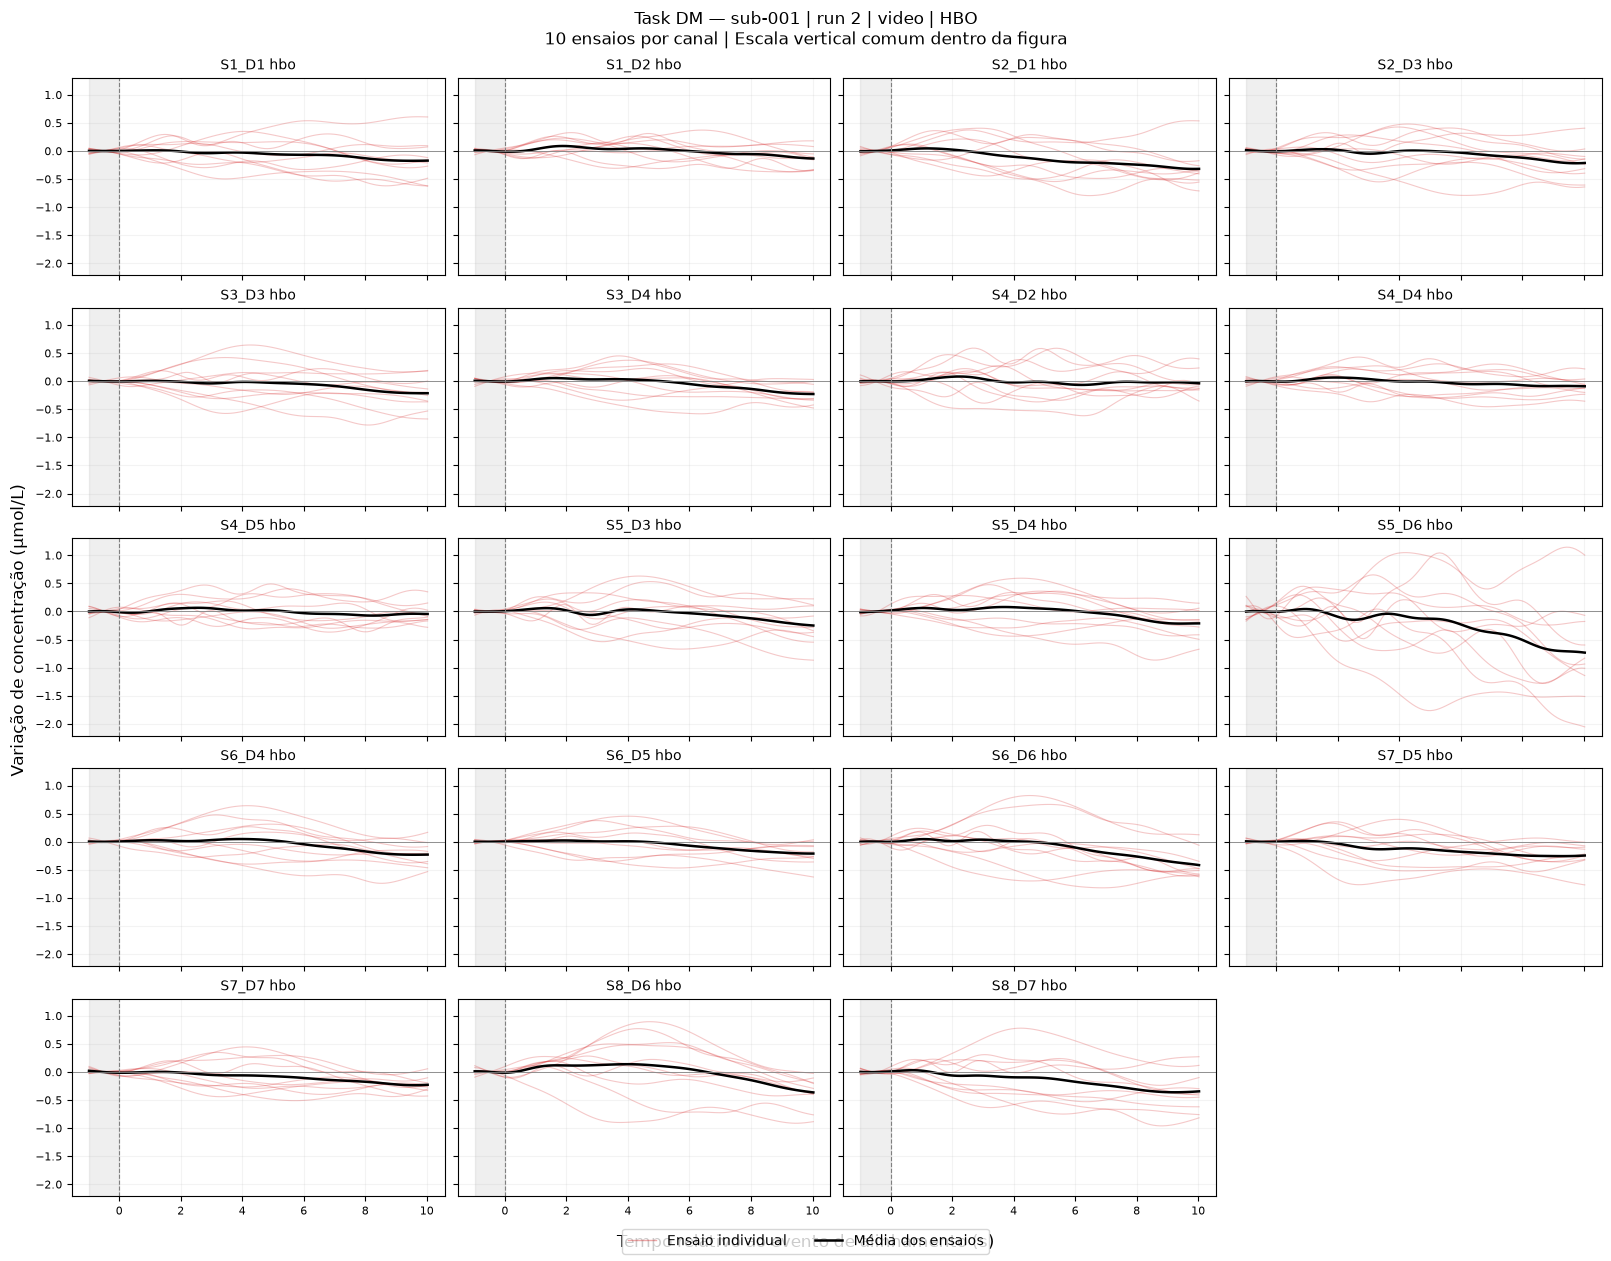

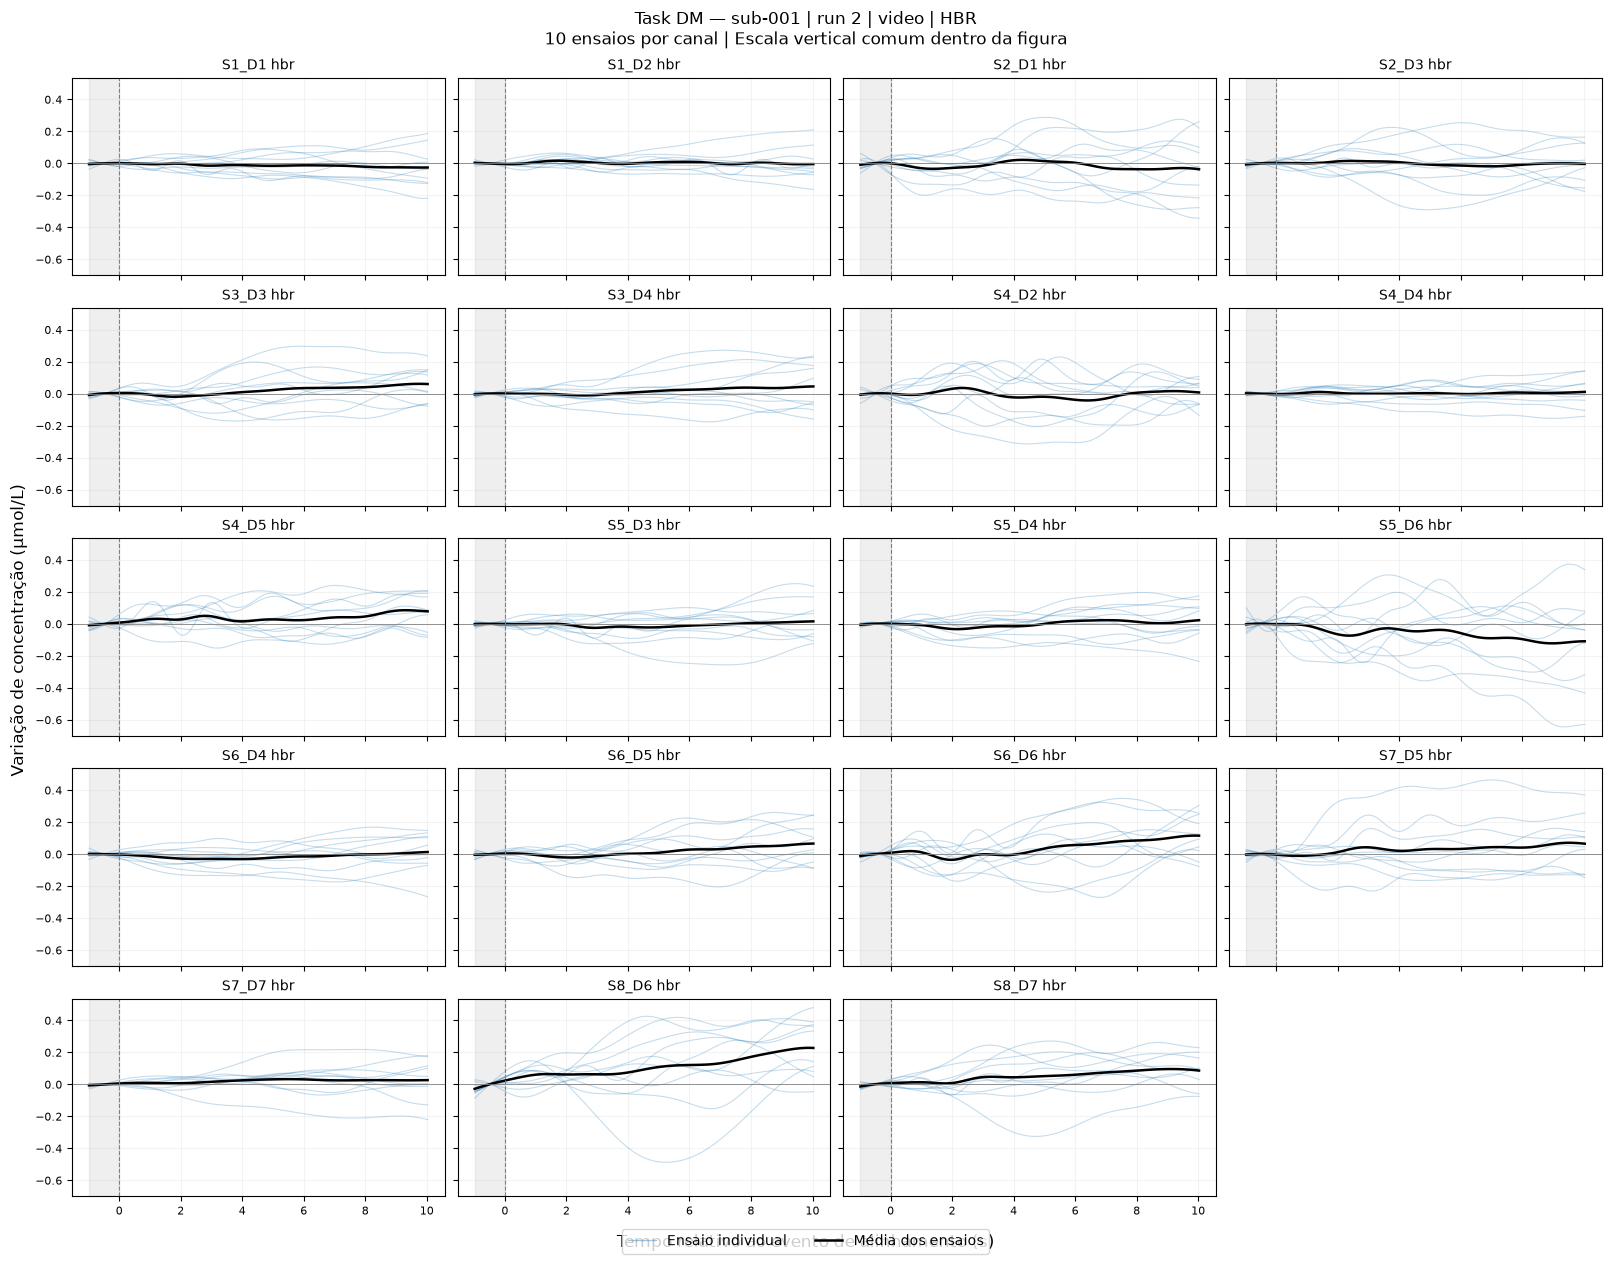


Nenhuma época ou canal rejeitado.
Objetos originais preservados e nenhum ficheiro escrito.


In [10]:
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


for nome in ["epochs_edm3", "df_edm5_verificacao"]:
    if nome not in globals():
        raise RuntimeError(f"Variável em falta: {nome}")

sujeito_edm7 = "sub-001"
run_edm7 = 2
fase_edm7 = "video"
versao_edm7 = "base"

chave_edm7 = (
    sujeito_edm7, run_edm7, fase_edm7, versao_edm7
)

if chave_edm7 not in epochs_edm3:
    raise RuntimeError(f"Objeto não encontrado: {chave_edm7}")

verificacao_edm7 = df_edm5_verificacao.loc[
    df_edm5_verificacao["sujeito"].eq(sujeito_edm7)
    & df_edm5_verificacao["run"].eq(run_edm7)
    & df_edm5_verificacao["fase"].eq(fase_edm7)
]

if (
    len(verificacao_edm7) != 1
    or not verificacao_edm7["baseline_compativel"].all()
):
    raise RuntimeError(
        "Esta combinação não tem correspondência de baseline confirmada."
    )

ep_edm7 = epochs_edm3[chave_edm7]
dados_edm7 = ep_edm7.copy().get_data() * 1e6
tempos_edm7 = ep_edm7.times
tipos_edm7 = ep_edm7.get_channel_types()

if not np.isfinite(dados_edm7).all():
    raise RuntimeError("Foram encontrados valores não finitos.")

print(
    f"ETAPA E-DM.7 — {sujeito_edm7} | run {run_edm7} | "
    f"{fase_edm7} | {versao_edm7}"
)
print(f"Épocas presentes: {len(dados_edm7)}")

for tipo, cor in [("hbo", "tab:red"), ("hbr", "tab:blue")]:
    indices = [
        i for i, t in enumerate(tipos_edm7) if t == tipo
    ]

    if not indices:
        print(f"Sem canais {tipo}.")
        continue

    n_colunas = 4
    n_linhas = math.ceil(len(indices) / n_colunas)

    fig, eixos = plt.subplots(
        n_linhas,
        n_colunas,
        figsize=(16, 2.5 * n_linhas),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, indice in zip(eixos.flat, indices):
        ensaios = dados_edm7[:, indice, :]

        ax.plot(
            tempos_edm7,
            ensaios.T,
            color=cor,
            alpha=0.25,
            linewidth=0.8,
        )
        ax.plot(
            tempos_edm7,
            ensaios.mean(axis=0),
            color="black",
            linewidth=1.8,
        )

        if ep_edm7.baseline is not None:
            inicio, fim = ep_edm7.baseline
            inicio = ep_edm7.tmin if inicio is None else inicio
            fim = ep_edm7.tmax if fim is None else fim
            ax.axvspan(
                max(inicio, ep_edm7.tmin),
                min(fim, ep_edm7.tmax),
                color="grey",
                alpha=0.12,
            )

        ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="grey", linewidth=0.6)
        ax.set_title(ep_edm7.ch_names[indice], fontsize=10)
        ax.grid(alpha=0.15)
        ax.tick_params(labelsize=8)

    for ax in list(eixos.flat)[len(indices):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Task DM — {sujeito_edm7} | run {run_edm7} | "
        f"{fase_edm7} | {tipo.upper()}\n"
        f"{len(dados_edm7)} ensaios por canal | "
        "Escala vertical comum dentro da figura"
    )
    fig.supxlabel("Tempo relativo ao evento de alinhamento (s)")
    fig.supylabel("Variação de concentração (µmol/L)")

    fig.legend(
        handles=[
            Line2D(
                [0], [0], color=cor, alpha=0.4,
                linewidth=1, label="Ensaio individual",
            ),
            Line2D(
                [0], [0], color="black",
                linewidth=1.8, label="Média dos ensaios",
            ),
        ],
        loc="outside lower center",
        ncol=2,
    )

    plt.show()

print("\nNenhuma época ou canal rejeitado.")
print("Objetos originais preservados e nenhum ficheiro escrito.")

### Etapa E-DM.7 — Continuação: sub-001, run 2, decisão

#### Objetivo
Inspecionar os ensaios individuais por canal das épocas alinhadas
à decisão na segunda run do `sub-001`.

#### Configuração
- Task: decision-making (DM).
- Participante: `sub-001`.
- Run: 2.
- Fase de alinhamento: `decisao`.
- Versão: `base`.

#### Visualização
- Uma figura para HbO e outra para HbR.
- Linhas finas: ensaios individuais.
- Linha preta: média dos ensaios.
- Escala vertical comum aos canais dentro de cada figura.

#### Limites
- Os limites verticais podem diferir dos das figuras anteriores.
- A baseline pré-decisão está temporalmente no vídeo anterior.
- A janela inclui o intervalo 130–150, a fixação pós-resposta
  e tempo após o início da fase seguinte.
- Não se interpreta a curva como um efeito exclusivo da decisão.
- Não se rejeitam épocas ou canais.
- Não se alteram os objetos originais e não se escrevem ficheiros.

Loading data for 10 events and 113 original time points ...
ETAPA E-DM.7 — sub-001 | run 2 | decisao | base
Épocas presentes: 10


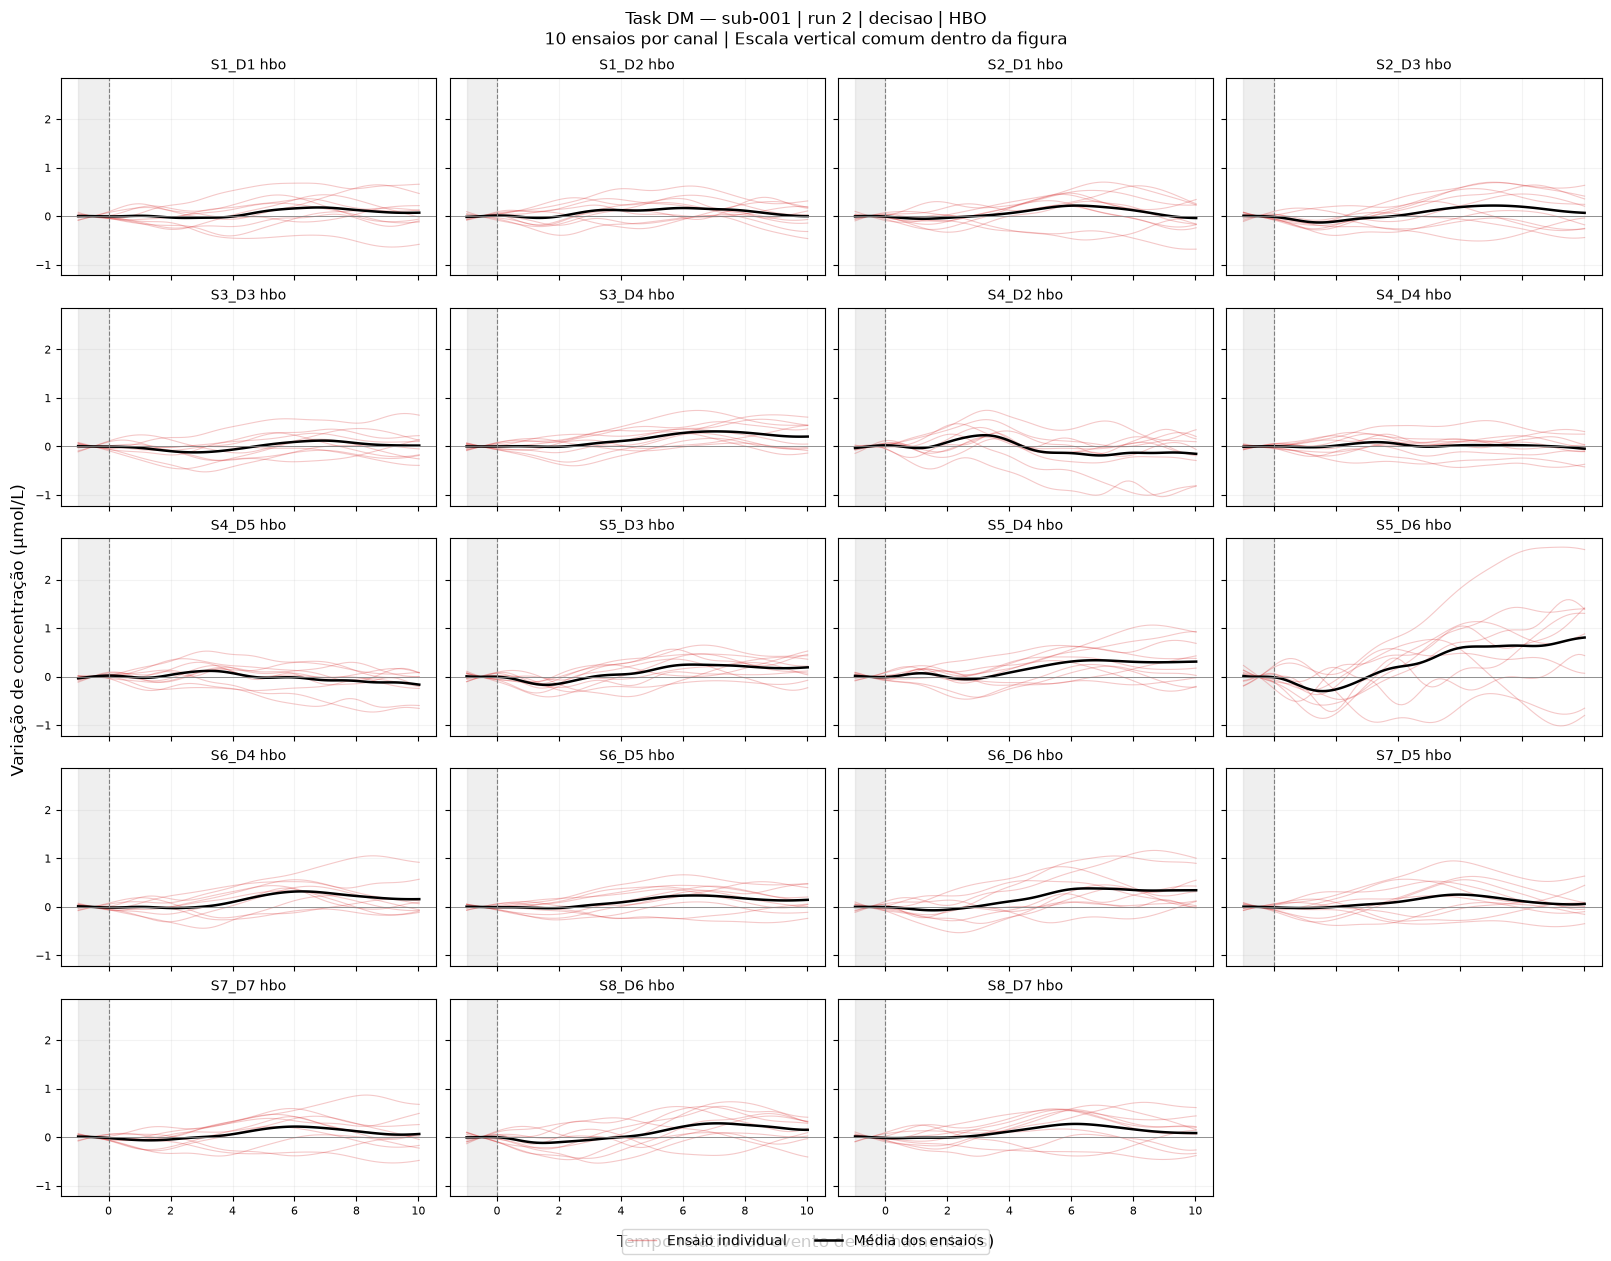

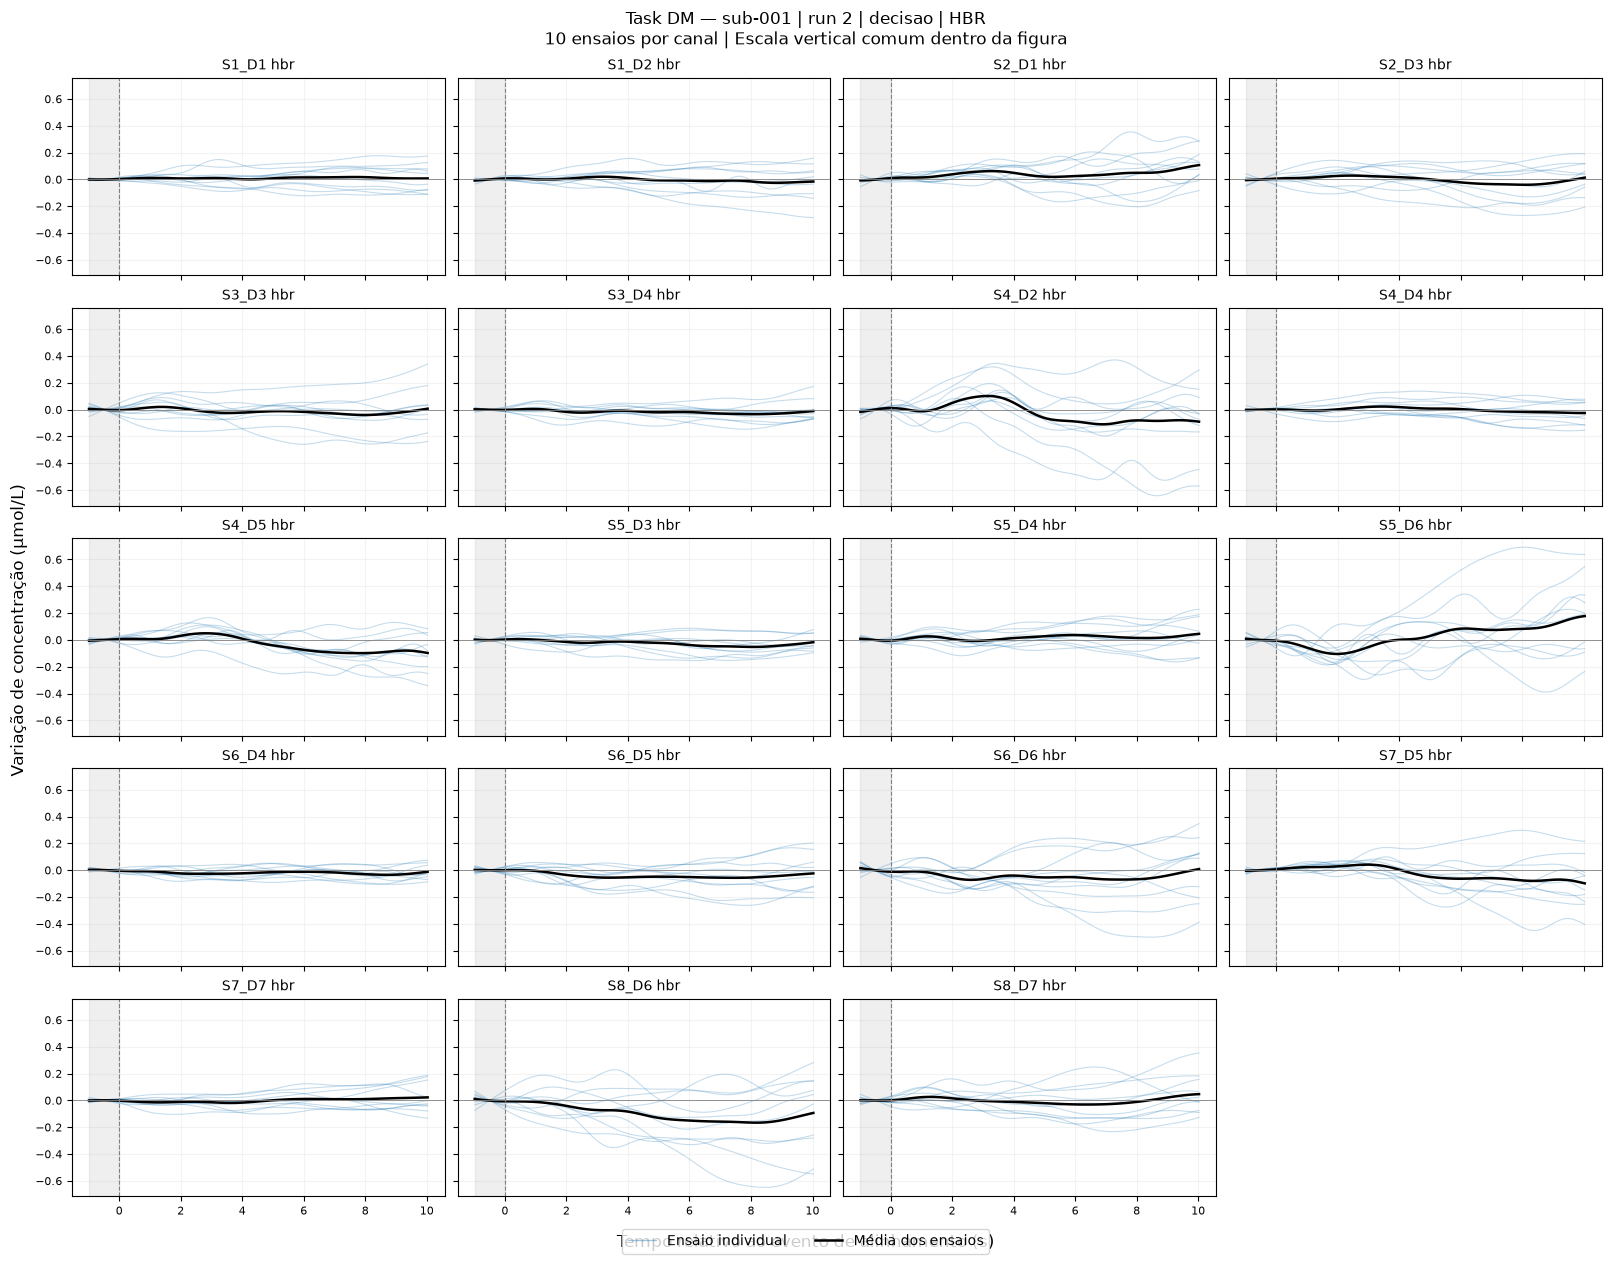


Nenhuma época ou canal rejeitado.
Objetos originais preservados e nenhum ficheiro escrito.


In [11]:
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


for nome in ["epochs_edm3", "df_edm5_verificacao"]:
    if nome not in globals():
        raise RuntimeError(f"Variável em falta: {nome}")

sujeito_edm7 = "sub-001"
run_edm7 = 2
fase_edm7 = "decisao"
versao_edm7 = "base"

chave_edm7 = (
    sujeito_edm7, run_edm7, fase_edm7, versao_edm7
)

if chave_edm7 not in epochs_edm3:
    raise RuntimeError(f"Objeto não encontrado: {chave_edm7}")

verificacao_edm7 = df_edm5_verificacao.loc[
    df_edm5_verificacao["sujeito"].eq(sujeito_edm7)
    & df_edm5_verificacao["run"].eq(run_edm7)
    & df_edm5_verificacao["fase"].eq(fase_edm7)
]

if (
    len(verificacao_edm7) != 1
    or not verificacao_edm7["baseline_compativel"].all()
):
    raise RuntimeError(
        "Esta combinação não tem correspondência de baseline confirmada."
    )

ep_edm7 = epochs_edm3[chave_edm7]
dados_edm7 = ep_edm7.copy().get_data() * 1e6
tempos_edm7 = ep_edm7.times
tipos_edm7 = ep_edm7.get_channel_types()

if not np.isfinite(dados_edm7).all():
    raise RuntimeError("Foram encontrados valores não finitos.")

print(
    f"ETAPA E-DM.7 — {sujeito_edm7} | run {run_edm7} | "
    f"{fase_edm7} | {versao_edm7}"
)
print(f"Épocas presentes: {len(dados_edm7)}")

for tipo, cor in [("hbo", "tab:red"), ("hbr", "tab:blue")]:
    indices = [
        i for i, t in enumerate(tipos_edm7) if t == tipo
    ]

    if not indices:
        print(f"Sem canais {tipo}.")
        continue

    n_colunas = 4
    n_linhas = math.ceil(len(indices) / n_colunas)

    fig, eixos = plt.subplots(
        n_linhas,
        n_colunas,
        figsize=(16, 2.5 * n_linhas),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, indice in zip(eixos.flat, indices):
        ensaios = dados_edm7[:, indice, :]

        ax.plot(
            tempos_edm7,
            ensaios.T,
            color=cor,
            alpha=0.25,
            linewidth=0.8,
        )
        ax.plot(
            tempos_edm7,
            ensaios.mean(axis=0),
            color="black",
            linewidth=1.8,
        )

        if ep_edm7.baseline is not None:
            inicio, fim = ep_edm7.baseline
            inicio = ep_edm7.tmin if inicio is None else inicio
            fim = ep_edm7.tmax if fim is None else fim
            ax.axvspan(
                max(inicio, ep_edm7.tmin),
                min(fim, ep_edm7.tmax),
                color="grey",
                alpha=0.12,
            )

        ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="grey", linewidth=0.6)
        ax.set_title(ep_edm7.ch_names[indice], fontsize=10)
        ax.grid(alpha=0.15)
        ax.tick_params(labelsize=8)

    for ax in list(eixos.flat)[len(indices):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Task DM — {sujeito_edm7} | run {run_edm7} | "
        f"{fase_edm7} | {tipo.upper()}\n"
        f"{len(dados_edm7)} ensaios por canal | "
        "Escala vertical comum dentro da figura"
    )
    fig.supxlabel("Tempo relativo ao evento de alinhamento (s)")
    fig.supylabel("Variação de concentração (µmol/L)")

    fig.legend(
        handles=[
            Line2D(
                [0], [0], color=cor, alpha=0.4,
                linewidth=1, label="Ensaio individual",
            ),
            Line2D(
                [0], [0], color="black",
                linewidth=1.8, label="Média dos ensaios",
            ),
        ],
        loc="outside lower center",
        ncol=2,
    )

    plt.show()

print("\nNenhuma época ou canal rejeitado.")
print("Objetos originais preservados e nenhum ficheiro escrito.")